# **Coin Detection, Classification, and Counting**

## Image Processing and Computer Vision - Assignment Module #1


Daniele Spezialetti 0001208524 daniele.spezialetti@studio.unibo.it

Lorenzo Cardesi (matricola) (email)

Alex Shchokin (matricola) (email)

---

## 1. Problem and Approach

We are given 142 photographs of Euro coins and one clean reference picture per denomination. The pipeline must:
- find every coin, despite textured backgrounds, uneven light and injected noise,
- tell which of the 8 denominations it is,
- add up the value of each picture and of the whole set,
- use only classical computer-vision methods (no deep learning).

### 1.1 Why a single cue is not enough

| Cue | What it can tell apart | Where it stops working |
|---|---|---|
| Shape | coin vs. background | every denomination is a disc |
| Colour | copper (1c, 2c, 5c) / gold (10c, 20c, 50c) / bimetallic (1€, 2€); inside the bimetallic pair, silver-core 1€ vs golden-core 2€ | nothing inside the copper or the gold family |
| Engraving | the design of each denomination | low metal relief: its appearance follows the light direction and reflections |
| Diameter | coins of the same alloy | the absolute size depends on the camera distance (only the size *ratios* between coins of the same picture can be used) |

The pipeline uses all four, each for the job it does best:
- **Shape (localisation):** Hough Circle Transform, followed by a gradient-driven correction of every circle.
- **Colour (alloy family):** median CIELAB values in a central disc and an outer ring give the family and, for bimetallic coins, 1€ vs 2€.
- **Engraving (polar descriptor):** local keypoints (SIFT, for example) were the obvious candidate, but on shiny, worn metal they move with the light. We use a global signature instead: the gradient magnitude of the coin resampled on a polar grid. A rotation of the coin becomes a cyclic shift along the angle axis, and the FFT tests all shifts in a single pass.
- **Diameter (relative size):** the polar signature is scale-normalised, so it cannot see size, yet size is what best separates, say, 20c from 50c. Coins lying in the same picture keep their size ratios, so the radii of the other coins tell us which denomination fits.

### 1.2 Soft rather than hard decisions

None of these cues is reliable alone in every image, so no stage makes a final yes/no call on its own. Colour thresholds are replaced by sigmoids: a coin close to a threshold keeps part of its score on both sides, and a strong descriptor match or the size check can still move it to the right family.

### 1.3 Roadmap

<img src="https://raw.githubusercontent.com/danielespezialetti/assignment-one-ipcv/main/architecture.png" alt= "diagram" width="40%">


| Stage | Produces | Section |
|---|---|---|
| Detection (same detector for both sets) | circles (centre, radius) | 4 |
| Reference templates | 8 polar descriptors | 5 |
| Colour measurement | $d_{ab}$, $\Delta b$, hue angle $h$ | 6.1 |
| Colour groups (parameters from the 8 references) | $P(\text{cu})$, $P(\text{au})$, $P(\text{bi})$, $P(2€ \mid \text{bi})$ | 6.2 |
| Polar matching | distance to the 8 templates | 6.3 |
| Fusion of colour and descriptor | one score per denomination | 6.4 |
| Relative size | one denomination per coin | 6.5 |
| Running the pipeline on the target set | value of each coin, partial and total amounts | 7 |
| Evaluation against the annotations | detection, classification and money metrics, ablations | 8 |

In [1]:
import os
from pathlib import Path

try:
    import google.colab
    IS_COLAB = True
except ImportError:
    IS_COLAB = False

if IS_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

    DRIVE_DIR = "/content/drive/MyDrive/AssignmentsIPCV"
    !cp -r {DRIVE_DIR}/coin_dataset.zip ./
    !unzip -q -o coin_dataset.zip

DATASET_DIR = Path(os.environ.get("COIN_DATASET_DIR", "coin_dataset"))
REF_DIR = DATASET_DIR / "reference_set"
TARGET_DIR = DATASET_DIR / "target_set"
# Our hand-made annotations (read in Section 8 only), shared on Google Drive as "Anyone with the link"
ANN_GDRIVE_ID = "1d2ZnfeAl_82Xrt31yWhykXJ8LZjDYnZU"
ANN_CSV = Path(os.environ.get("COIN_ANN_CSV", "coin_annotations.csv"))
if not ANN_CSV.exists():
    import gdown
    gdown.download(id=ANN_GDRIVE_ID, output=str(ANN_CSV), quiet=False)

for folder in (REF_DIR, TARGET_DIR):
    if not folder.is_dir():
        raise FileNotFoundError(f"Dataset folder not found: {folder.resolve()}")
if not ANN_CSV.is_file():
    raise FileNotFoundError(f"Annotations not found: {ANN_CSV.resolve()}")
print(f"Environment: {'Colab' if IS_COLAB else 'local'} | dataset: {DATASET_DIR.resolve()}")

Mounted at /content/drive


Downloading...
From: https://drive.google.com/uc?id=1d2ZnfeAl_82Xrt31yWhykXJ8LZjDYnZU
To: /content/coin_annotations.csv
100%|██████████| 15.7k/15.7k [00:00<00:00, 24.9MB/s]

Environment: Colab | dataset: /content/coin_dataset


## 2. Setup

Libraries, plus the few facts about Euro coins that the pipeline takes as given: nominal diameters, face values and the split into three alloy families.

In [2]:
import re
import itertools
from dataclasses import dataclass
from typing import Dict, List, Optional, Tuple

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment

# Nominal diameters [mm] from the official coin specifications
COIN_DIAMETERS = {
    "1cent": 16.25, "2cent": 18.75, "5cent": 21.25,
    "10cent": 19.75, "20cent": 22.25, "50cent": 24.25,
    "1euro": 23.25, "2euro": 25.75,
}

# Face values in integer cents (no floating-point rounding in the sums)
VALUE_CENTS = {
    "1cent": 1, "2cent": 2, "5cent": 5,
    "10cent": 10, "20cent": 20, "50cent": 50,
    "1euro": 100, "2euro": 200,
}

DENOMINATIONS = ["1cent", "2cent", "5cent", "10cent", "20cent", "50cent", "1euro", "2euro"]

# Alloy families: cu = copper-coloured, au = Nordic gold, bi = two metals
GROUPS = {
    "cu": ["1cent", "2cent", "5cent"],
    "au": ["10cent", "20cent", "50cent"],
    "bi": ["1euro", "2euro"],
}
GROUP_OF = {label: g for g, labels in GROUPS.items() for label in labels}
GROUP_NAMES = {"cu": "copper", "au": "gold", "bi": "bimetallic"}
GROUP_COLORS = {"cu": "#c0622b", "au": "#d9a400", "bi": "#4c78a8"}


def natural_key(path: Path) -> int:
    # numeric order, so that image_10 comes after image_9
    match = re.search(r"\d+", path.stem)
    return int(match.group()) if match else 0


def to_rgb(img_bgr: np.ndarray) -> np.ndarray:
    # matplotlib wants RGB
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

## 3. A First Look at the Target Set

Besides the usual real-world clutter (textured backgrounds, shadows, uneven lighting, coins touching each other), browsing the target images reveals two artefacts that were clearly added on purpose:

- **Red and blue are swapped in the target files.** Displayed the same way, the reference photos look natural while the targets look bluish. The swap is undone once, at load time (`load_target`).
- **Two kinds of noise are mixed.** At full zoom one sees isolated pixels of random colour (salt-and-pepper) on top of a finer Gaussian grain.

The noise is not removed once and for all: each later stage applies the filtering that suits its own purpose, because what counts as noise for circle detection (the engraving, for instance) is precisely the signal for the descriptor.

Target images: 142   reference images: 8


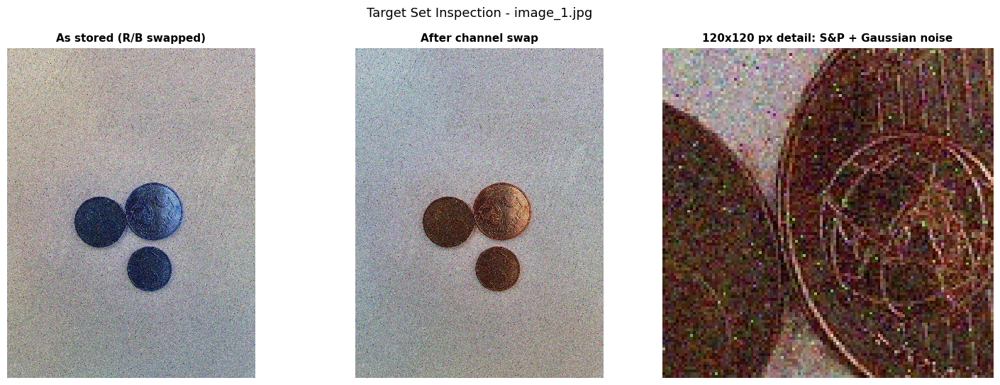

In [3]:
def read_image(path: Path) -> np.ndarray:
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise IOError(f"Cannot read image: {path}")
    return img


def load_target(path: Path) -> np.ndarray:
    # Target files store R and B swapped: reversing the channel axis gives a genuine BGR array
    return np.ascontiguousarray(read_image(path)[:, :, ::-1])


def load_reference(path: Path) -> np.ndarray:
    # References are ordinary BGR files
    return read_image(path)


target_paths = sorted(TARGET_DIR.glob("*.jpg"), key=natural_key)
print(f"Target images: {len(target_paths)}   reference images: {len(list(REF_DIR.glob('*.jpg')))}")

# Same scene three times: as stored, with channels fixed, and a crop where the noise is visible
sample_path = TARGET_DIR / "image_1.jpg"
raw = read_image(sample_path)
fixed = load_target(sample_path)
h, w = fixed.shape[:2]
zoom = fixed[h // 2 - 60:h // 2 + 60, w // 2 - 60:w // 2 + 60]

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, img, title in zip(axes, [raw, fixed, zoom],
                          ["As stored (R/B swapped)", "After channel swap", "120x120 px detail: S&P + Gaussian noise"]):
    ax.imshow(to_rgb(img), interpolation="nearest")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.axis("off")
plt.suptitle(f"Target Set Inspection - {sample_path.name}", fontsize=13)
plt.tight_layout()
plt.show()

## 4. Finding the Coins

The same detector is used on **both image sets**: it localises the single coin of each reference picture and all the coins of each target scene. It works in three steps: clean the image, propose circles with Hough, correct each proposal.

### 4.1 Cleaning the image for Hough

`HOUGH_GRADIENT` votes along gradient directions, so anything that produces gradients other than the coin outline (noise, the reliefs inside the coin, background texture) creates wrong votes. Preprocessing aims at an image made of flat regions separated by sharp coin borders:

| Step | Operation | Purpose |
|---|---|---|
| 1 | take $L^*$ from CIELAB | brightness only |
| 2 | CLAHE on $L^*$ (clip $1.5$, $8 \times 8$ tiles) | lift the coins lying in shadow |
| 3 | median filter $9 \times 9$ | remove salt-and-pepper; the large kernel also erases the fine engravings |
| 4 | Non-Local Means, $h = 15$ | remove the remaining Gaussian grain; NLM averages similar patches, so it does not smear the rim |

No Gaussian blur is added at the end. After median and NLM the borders are already clean, and more smoothing would only widen the edge on which the votes are cast.

### 4.2 Hough parameters

The preprocessing parameters above and the Hough parameters below were tuned by visually inspecting the detections on the target set (no annotations involved), with the physical setup as a guide:

- `minRadius = 50`, `maxRadius = 120`: the radii (px) at which coins appear in the target set (portrait images, $720 \times 960$ px, width $\times$ height).
- `minDist = 80`: a bit less than the smallest coin diameter, so two touching coins are both kept while duplicates of one coin are merged.
- `param1 = 60` (upper Canny threshold), `param2 = 50` (accumulator threshold): deliberately strict, because a spurious circle gets a label and adds money to the total.

**Operating range:** the descriptor of Section 5 is scale-normalised, but the pipeline as a whole is not scale-invariant: a coin imaged at less than 50 px or more than 120 px of radius is never proposed, hence never classified.

In [ ]:
@dataclass(frozen=True)
class Circle:
    cx: float
    cy: float
    r: float


DETECTION_PREPROC = dict(clip_limit=1.5, median_ksize=9, nlm_h=15)
HOUGH_PARAMS = dict(dp=1.3, minDist=80, param1=60, param2=50, minRadius=50, maxRadius=120)


def preprocess_for_detection(img_bgr: np.ndarray, return_stages: bool = False):
    # Luminance-only pipeline whose output feeds the Hough detector
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=DETECTION_PREPROC["clip_limit"], tileGridSize=(8, 8))
    enhanced_bgr = cv2.cvtColor(cv2.merge((clahe.apply(l), a, b)), cv2.COLOR_LAB2BGR)
    enhanced_l = cv2.cvtColor(enhanced_bgr, cv2.COLOR_BGR2LAB)[:, :, 0]

    # impulsive noise first (median), Gaussian grain second (NLM)
    median = cv2.medianBlur(enhanced_l, DETECTION_PREPROC["median_ksize"])
    denoised = cv2.fastNlMeansDenoising(median, None, h=DETECTION_PREPROC["nlm_h"],
                                        templateWindowSize=7, searchWindowSize=21)
    if return_stages:
        return {"L*": l, "CLAHE": enhanced_l, "Median 9x9": median, "Non-Local Means": denoised}
    return denoised


def hough_circles(preprocessed: np.ndarray) -> List[Circle]:
    circles = cv2.HoughCircles(preprocessed, cv2.HOUGH_GRADIENT, **HOUGH_PARAMS)
    if circles is None:
        return []
    return [Circle(*map(float, c)) for c in np.around(circles[0])]

### 4.3 Correcting each circle

Hough estimates are coarse (votes on a grid of resolution `dp = 1.3`, over a heavily smoothed image), and a few pixels of error already hurt downstream: the colour ring leaks onto the background, the polar grid is off-centre, and the size comparison uses wrong radii.

Every Hough circle is therefore treated as a *proposal*, and a better circle is searched nearby. On the real border of a coin the gradient points **along the radius**, so for a candidate circle we take $180$ points on its circumference and measure the radial component of the Sobel gradient:

$$g_{\text{rad}}(\theta) = \left| \, G_x(\theta) \cos\theta + G_y(\theta) \sin\theta \, \right|$$

The **boundary score** of the candidate is the *median* of $g_{\text{rad}}$ along the circle, so a highlight, a shadow or a touching coin, which only affect a few samples, are ignored. We try $5 \times 5$ centre offsets (within $\pm 6\%$ of the radius) and $9$ radii (within $\pm 10\%$), keeping only the candidates whose centre moves by at most $8\%$ of the radius and whose radius changes by at most $10\%$ (so the four corners of the offset grid, at $6\sqrt{2} \approx 8.5\%$, are skipped). The best of these candidates replaces the proposal only if it improves the score by at least $5\%$. These ranges were also set by looking at the target set.

**What refinement cannot do.** Hough remains the actual detector: refinement neither recovers a missed coin nor removes a spurious circle. It can also lock on to the wrong edge, such as the junction between the two alloys of a bimetallic coin or the border of a cast shadow, and a heavily occluded rim lowers the median score so much that no candidate wins. Section 8.4 measures what the correction is worth for classification.

In [5]:
REFINE_PARAMS = dict(center_shift_frac=0.06, radius_band_frac=0.10, n_center_steps=5, n_radius_steps=9, n_angles=180)
ACCEPT_PARAMS = dict(min_relative_gain=0.05, max_center_shift_frac=0.08, max_radius_change_frac=0.10)


def radial_gradient(img_bgr: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    # Gx, Gy of a lightly smoothed grey image
    gray = cv2.GaussianBlur(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    return cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3), cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)


def boundary_score(gx: np.ndarray, gy: np.ndarray, c: Circle, cos_t: np.ndarray, sin_t: np.ndarray) -> float:
    # Median |radial gradient| along the circle; -inf if the circle is mostly off-frame
    h, w = gx.shape
    xs, ys = c.cx + c.r * cos_t, c.cy + c.r * sin_t
    valid = (xs >= 1) & (xs < w - 1) & (ys >= 1) & (ys < h - 1)
    if valid.mean() < 0.90:
        return -np.inf
    xi, yi = np.rint(xs[valid]).astype(np.int32), np.rint(ys[valid]).astype(np.int32)
    radial = gx[yi, xi] * cos_t[valid] + gy[yi, xi] * sin_t[valid]
    return float(np.median(np.abs(radial)))


def refine_circle(gx: np.ndarray, gy: np.ndarray, c: Circle) -> Circle:
    # Exhaustive search near the proposal; the proposal is kept unless the gain is convincing
    p = REFINE_PARAMS
    theta = np.linspace(0, 2 * np.pi, p["n_angles"], endpoint=False)
    cos_t, sin_t = np.cos(theta).astype(np.float32), np.sin(theta).astype(np.float32)
    max_shift = max(1.0, p["center_shift_frac"] * c.r)
    max_dr = max(1.0, p["radius_band_frac"] * c.r)
    shifts = np.linspace(-max_shift, max_shift, p["n_center_steps"])
    dradii = np.linspace(-max_dr, max_dr, p["n_radius_steps"])

    # only candidates within the shift and radius limits are considered (small tolerance for rounding)
    a, tol = ACCEPT_PARAMS, 1e-9
    score_init = boundary_score(gx, gy, c, cos_t, sin_t)
    best, best_score = c, score_init
    for dx, dy, dr in itertools.product(shifts, shifts, dradii):
        if (np.hypot(dx, dy) > a["max_center_shift_frac"] * c.r + tol
                or abs(dr) > a["max_radius_change_frac"] * c.r + tol):
            continue
        cand = Circle(float(c.cx + dx), float(c.cy + dy), float(c.r + dr))
        score = boundary_score(gx, gy, cand, cos_t, sin_t)
        if score > best_score:
            best, best_score = cand, score
    if not np.isfinite(best_score):
        return c

    # the best admissible candidate replaces the proposal only if the gain is convincing
    gain = np.inf if not np.isfinite(score_init) else (best_score - score_init) / max(score_init, 1e-6)
    if gain < a["min_relative_gain"]:
        return c
    return Circle(float(round(best.cx)), float(round(best.cy)), float(round(best.r)))


def detect_coins(img_bgr: np.ndarray, return_raw: bool = False):
    # Detection entry point, used for both image sets
    raw = hough_circles(preprocess_for_detection(img_bgr))
    gx, gy = radial_gradient(img_bgr)
    refined = [refine_circle(gx, gy, c) for c in raw]
    return (refined, raw) if return_raw else refined

First, the four preprocessing stages on one scene: noise and inner reliefs fade, while the coin borders survive. Then, detections on four scenes; in the bottom row, the coin whose circle was corrected the most is enlarged (dashed red: Hough proposal, solid green: refined circle).

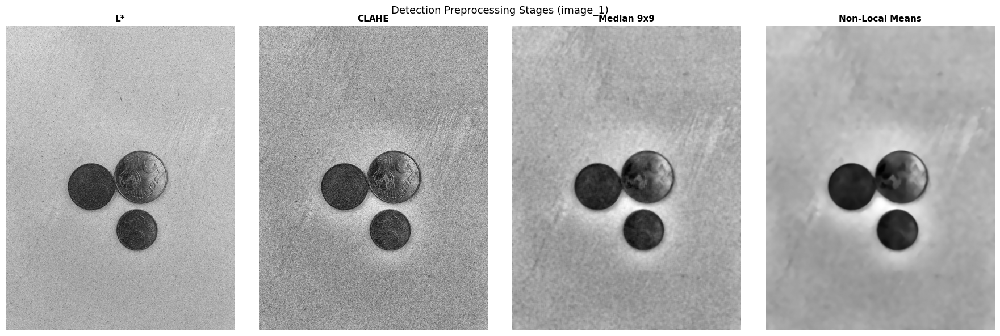

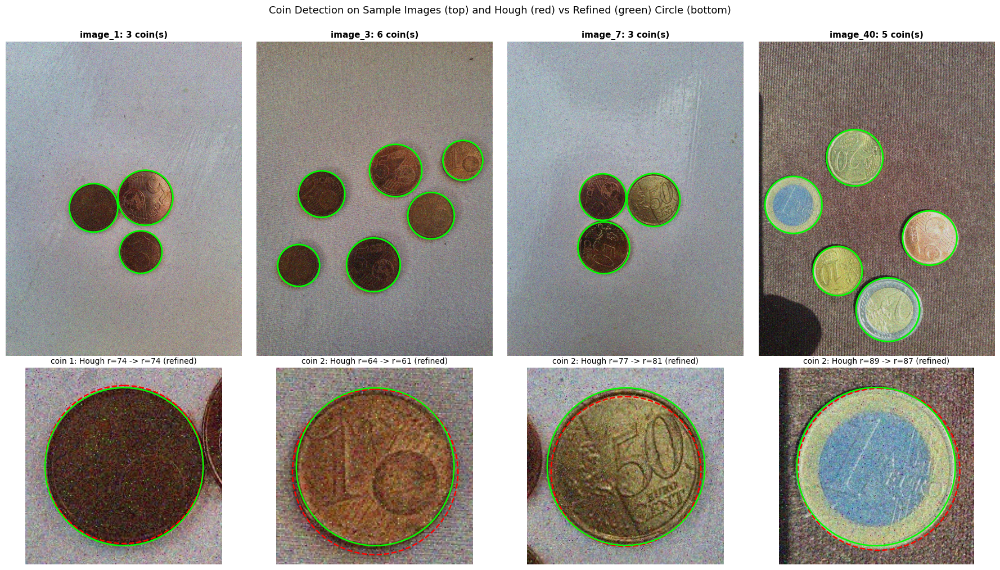

In [6]:
sample_img = load_target(TARGET_DIR / "image_1.jpg")
stages = preprocess_for_detection(sample_img, return_stages=True)

fig, axes = plt.subplots(1, 4, figsize=(18, 6))
for ax, (name, im) in zip(axes, stages.items()):
    ax.imshow(im, cmap="gray")
    ax.set_title(name, fontsize=11, fontweight="bold")
    ax.axis("off")
plt.suptitle("Detection Preprocessing Stages (image_1)", fontsize=13)
plt.tight_layout()
plt.show()

# Top row: detections. Bottom row: the coin whose circle changed most after refinement
demo_names = ["image_1", "image_3", "image_7", "image_40"]
fig, axes = plt.subplots(2, 4, figsize=(18, 10), gridspec_kw={"height_ratios": [1.6, 1]})
for k, name in enumerate(demo_names):
    img = load_target(TARGET_DIR / f"{name}.jpg")
    refined, raw = detect_coins(img, return_raw=True)

    ax = axes[0, k]
    ax.imshow(to_rgb(img))
    for c in refined:
        ax.add_patch(plt.Circle((c.cx, c.cy), c.r, fill=False, ec="lime", lw=2))
    ax.set_title(f"{name}: {len(refined)} coin(s)", fontsize=11, fontweight="bold")
    ax.axis("off")

    # largest correction = centre shift + radius change
    moved = [abs(r.cx - h.cx) + abs(r.cy - h.cy) + abs(r.r - h.r) for r, h in zip(refined, raw)]
    i = int(np.argmax(moved))
    c, hc = refined[i], raw[i]
    m = int(1.25 * c.r)
    x0, y0 = int(max(c.cx - m, 0)), int(max(c.cy - m, 0))
    ax = axes[1, k]
    ax.imshow(to_rgb(img[y0:int(c.cy + m), x0:int(c.cx + m)]))
    ax.add_patch(plt.Circle((hc.cx - x0, hc.cy - y0), hc.r, fill=False, ec="red", lw=1.8, ls="--"))
    ax.add_patch(plt.Circle((c.cx - x0, c.cy - y0), c.r, fill=False, ec="lime", lw=1.8))
    status = "refined" if c != hc else "unchanged"
    ax.set_title(f"coin {i}: Hough r={hc.r:.0f} -> r={c.r:.0f} ({status})", fontsize=10)
    ax.axis("off")

plt.suptitle("Coin Detection on Sample Images (top) and Hough (red) vs Refined (green) Circle (bottom)",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 5. Reference Templates

Each reference photo shows a single coin on a clean background, so the detector of Section 4 finds it without any special handling; references and targets are then cropped by exactly the same rule. Every reference coin is turned into a **polar descriptor**, the template against which target coins are matched.

### 5.1 Building the polar descriptor

The descriptor must describe the engraving while being as insensitive as possible to rotation, scale and lighting:

1. **Crop** a $2r \times 2r$ square around the coin.
2. **Prefilter**: the background outside the disc is filled with the median grey of the coin (so the rim does not create an artificial edge), then a $3 \times 3$ Gaussian and a mild CLAHE.
3. **Gradient magnitude** instead of intensity, which depends much less on how bright the metal looks.
4. **Polar resampling** (`cv2.warpPolar`) on $180$ angles $\times$ $96$ radii. A rotation of the coin becomes a **cyclic shift along $\theta$**, and the fixed number of radial samples makes the result independent of the coin size. The outer rim (beyond $85\%$ of the radius, identical on every coin) and the very centre (below $12\%$, mostly interpolation) are dropped.
5. **Per-angle z-score**: every radial profile is shifted to zero mean and unit variance. Under directional light one half of the coin has much stronger edges than the other, and standardising every direction separately cancels this slow imbalance. The price is that a weak, noisy direction is scaled up to the same weight as a strongly informative one (the $10^{-6}$ floor only prevents a division by zero).

### 5.2 Comparing two descriptors regardless of rotation

For a reference $A$ and a target $B$ we compute the Pearson correlation at every cyclic shift $s$ of the angular axis and keep the best one:

$$d(A, B) = 1 - \max_{s} \; \frac{\frac{1}{N} \sum_{\theta, \rho} A(\theta, \rho) \, B(\theta - s, \rho) - \mu_A \mu_B}{\sigma_A \, \sigma_B}$$

There is no need to loop over the 180 shifts: by the correlation theorem, $\mathcal{F}^{-1}\left(\mathcal{F}(A) \cdot \overline{\mathcal{F}(B)}\right)$, with 1D FFTs along $\theta$ summed over the radii, yields all of them at once. $d$ lies in $[0, 2]$, and $0$ means identical up to a rotation. If one of the two arrays is constant, the correlation is undefined: the function then returns $0$ for every shift (distance $1$) instead of NaN.

In [ ]:
POLAR_ANGULAR_SAMPLES = 180   # one sample every 2 degrees
POLAR_RADIAL_SAMPLES = 96
POLAR_RADIUS_FRACTION = 0.85  # the rim is the same on all coins
POLAR_INNER_FRACTION = 0.12   # too few source pixels near the centre


def disk_mask(n: int) -> np.ndarray:
    # inscribed-disc mask for an n x n patch
    yy, xx = np.ogrid[:n, :n]
    return (yy - (n - 1) / 2) ** 2 + (xx - (n - 1) / 2) ** 2 <= (n / 2) ** 2


def crop_coin(img_bgr: np.ndarray, c: Circle) -> np.ndarray:
    # 2r x 2r patch around the coin
    d = int(2 * c.r)
    return cv2.getRectSubPix(img_bgr, (d, d), (float(c.cx), float(c.cy)))


def polar_prefilter(gray: np.ndarray, inside: np.ndarray, clip: float = 1.2) -> np.ndarray:
    # neutralise the background (median fill), then light smoothing and local equalisation
    g = gray.copy()
    g[~inside] = int(np.median(g[inside]))
    g = cv2.GaussianBlur(g, (3, 3), 0)
    return cv2.createCLAHE(clipLimit=clip, tileGridSize=(8, 8)).apply(g)


def coin_to_polar(crop_bgr: np.ndarray, return_stages: bool = False):
    # |gradient| -> polar grid (angle x radius) -> drop the inner radii -> z-score per angle
    gray = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2GRAY)
    enhanced = polar_prefilter(gray, disk_mask(gray.shape[0]))
    grad = cv2.magnitude(cv2.Sobel(enhanced, cv2.CV_32F, 1, 0, ksize=3),
                         cv2.Sobel(enhanced, cv2.CV_32F, 0, 1, ksize=3))
    h, w = grad.shape
    polar = cv2.warpPolar(grad, (POLAR_RADIAL_SAMPLES, POLAR_ANGULAR_SAMPLES), ((w - 1) / 2.0, (h - 1) / 2.0),
                          POLAR_RADIUS_FRACTION * min(h, w) / 2.0,
                          cv2.WARP_POLAR_LINEAR | cv2.INTER_LINEAR | cv2.WARP_FILL_OUTLIERS)
    start = int(POLAR_RADIAL_SAMPLES * POLAR_INNER_FRACTION / POLAR_RADIUS_FRACTION)
    polar = polar[:, start:]                                   # shape (180 angles, 83 radii)
    mu, sd = polar.mean(axis=1, keepdims=True), np.maximum(polar.std(axis=1, keepdims=True), 1e-6)
    polar = ((polar - mu) / sd).astype(np.float32)
    if return_stages:
        return polar, {"prefiltered": enhanced, "gradient": grad}
    return polar


def circular_correlation(ref: np.ndarray, tgt: np.ndarray) -> np.ndarray:
    # Pearson correlation between ref and np.roll(tgt, k, axis=0) for every k, via FFT
    denom = float(ref.std()) * float(tgt.std())
    if denom < 1e-12:
        return np.zeros(ref.shape[0])
    c = np.fft.ifft((np.fft.fft(ref, axis=0) * np.conj(np.fft.fft(tgt, axis=0))).sum(axis=1)).real
    return (c / tgt.size - ref.mean() * tgt.mean()) / denom


def polar_distance(ref: np.ndarray, tgt: np.ndarray) -> float:
    # 0 = identical up to a rotation
    return float(1.0 - circular_correlation(ref, tgt).max())

### 5.3 The template bank

The next cell localises the coin in each reference image and stores its descriptor. Three figures follow: the eight references, the steps of the descriptor for the 2€ coin, and all eight descriptors.

The references show the common face of each coin. In the polar images, the bundles of parallel lines become **periodic stripes along $\theta$**, the junction between the two alloys of 1€ and 2€ becomes a **horizontal band** near $72$–$75\%$ of the radius, and the large numerals turn into **wide arcs** spanning a large part of the angular axis rather than localised blobs.

Template bank ready: 8 descriptors of shape (180, 83) (angle x radius)


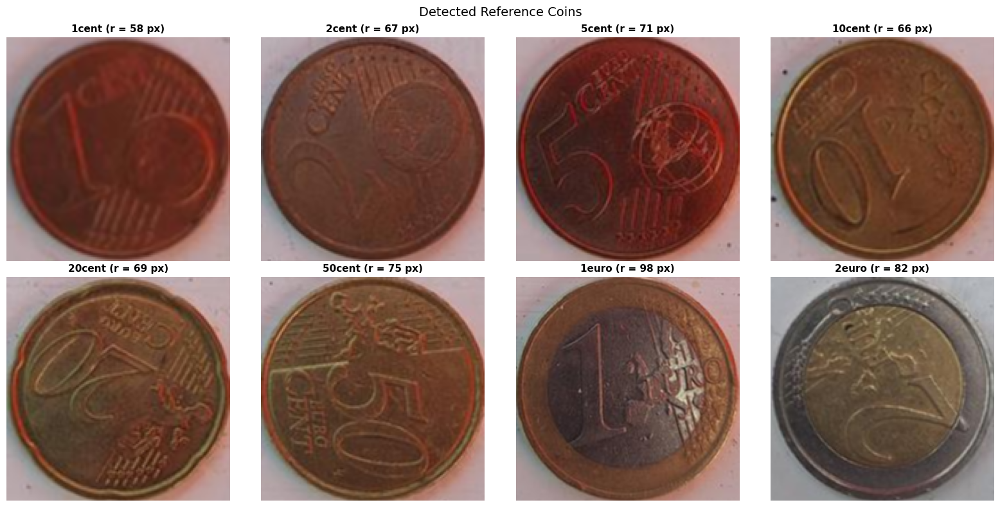

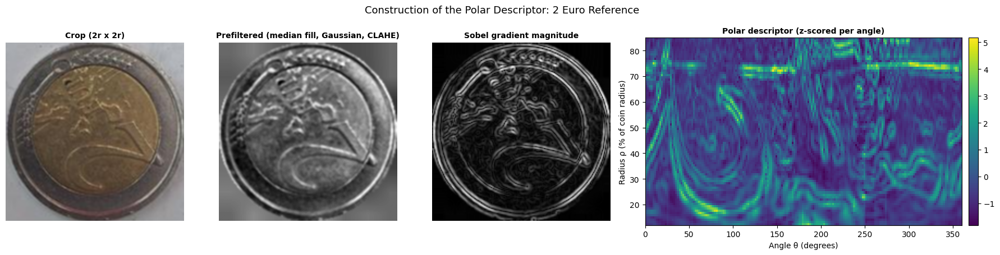

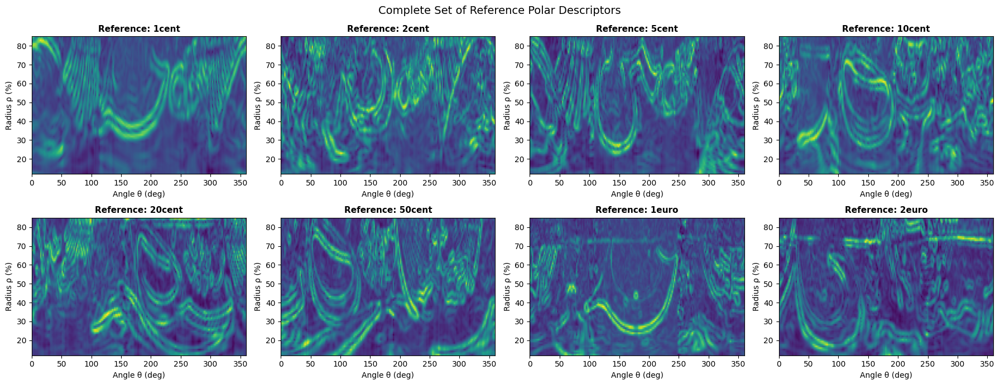

In [8]:
def locate_reference(img: np.ndarray, label: str) -> Circle:
    # The detector of Section 4; if several circles are found, keep the most central one
    circles = detect_coins(img)
    if not circles:
        raise RuntimeError(f"No coin found in reference {label}")
    h, w = img.shape[:2]
    return min(circles, key=lambda c: np.hypot(c.cx - w / 2, c.cy - h / 2))


ref_images, ref_circles, ref_crops, REF_POLARS = {}, {}, {}, {}
for label in DENOMINATIONS:
    img = load_reference(REF_DIR / f"{label}.jpg")
    ref_images[label] = img
    ref_circles[label] = locate_reference(img, label)
    ref_crops[label] = crop_coin(img, ref_circles[label])
    REF_POLARS[label] = coin_to_polar(ref_crops[label])
print(f"Template bank ready: {len(REF_POLARS)} descriptors of shape {REF_POLARS['1cent'].shape} (angle x radius)")


def polar_distances(img_bgr: np.ndarray, c: Circle) -> Dict[str, float]:
    # {denomination: polar distance} of one detected coin from the 8 templates
    tgt = coin_to_polar(crop_coin(img_bgr, c))
    return {label: polar_distance(REF_POLARS[label], tgt) for label in DENOMINATIONS}

# Figure 1: the eight localised references
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, label in zip(axes.flatten(), DENOMINATIONS):
    ax.imshow(to_rgb(ref_crops[label]))
    ax.set_title(f"{label} (r = {ref_circles[label].r:.0f} px)", fontsize=11, fontweight="bold")
    ax.axis("off")
plt.suptitle("Detected Reference Coins", fontsize=14)
plt.tight_layout()
plt.show()

# Figure 2: step-by-step construction of one descriptor (2 euro)
polar, st = coin_to_polar(ref_crops["2euro"], return_stages=True)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.9]})
axes[0].imshow(to_rgb(ref_crops["2euro"]))
axes[1].imshow(st["prefiltered"], cmap="gray")
axes[2].imshow(st["gradient"], cmap="gray")
for ax, t in zip(axes[:3], ["Crop (2r x 2r)", "Prefiltered (median fill, Gaussian, CLAHE)", "Sobel gradient magnitude"]):
    ax.set_title(t, fontsize=10, fontweight="bold")
    ax.axis("off")
im = axes[3].imshow(polar.T, aspect="auto", cmap="viridis", origin="lower", extent=[0, 360, 12, 85])
axes[3].set_title("Polar descriptor (z-scored per angle)", fontsize=10, fontweight="bold")
axes[3].set_xlabel("Angle θ (degrees)")
axes[3].set_ylabel("Radius ρ (% of coin radius)")
fig.colorbar(im, ax=axes[3], fraction=0.046, pad=0.02)
plt.suptitle("Construction of the Polar Descriptor: 2 Euro Reference", fontsize=13)
plt.tight_layout()
plt.show()

# Figure 3: the whole template bank
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, label in zip(axes.flatten(), DENOMINATIONS):
    ax.imshow(REF_POLARS[label].T, aspect="auto", cmap="viridis", origin="lower", extent=[0, 360, 12, 85])
    ax.set_title(f"Reference: {label}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Angle θ (deg)")
    ax.set_ylabel("Radius ρ (%)")
plt.suptitle("Complete Set of Reference Polar Descriptors", fontsize=14)
plt.tight_layout()
plt.show()

**Sanity check: can the descriptor tell the references apart?** The matrix holds the distance between every pair of references. Each reference is close only to itself (off-diagonal distances between $0.75$ and $0.97$); the nearest pair is 1c–2c, which carry the same design. On real target coins, with noise, wear and different lighting, even the distance from the *right* template stays well above zero, which is why the descriptor is always combined with colour and size.

Off-diagonal distances: 0.75 to 0.97; nearest pair: 1cent - 2cent


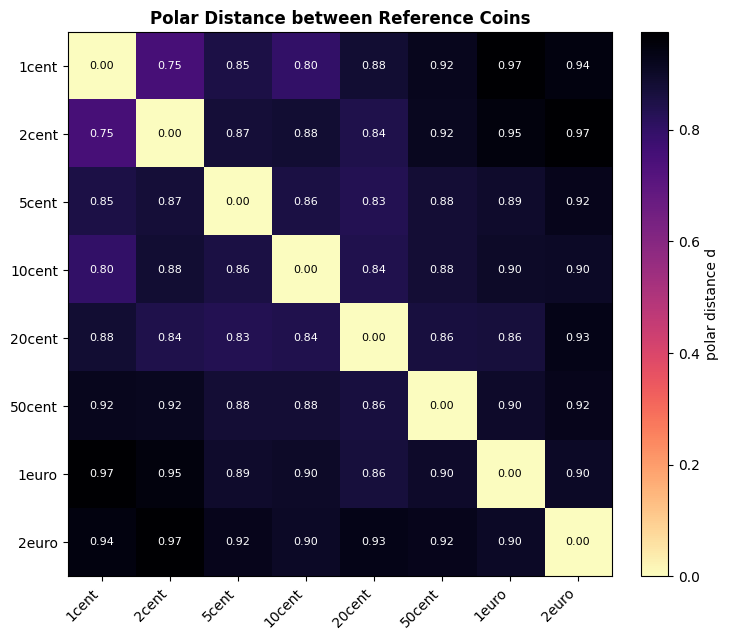

In [9]:
ref_dist = np.array([[polar_distance(REF_POLARS[a], REF_POLARS[b]) for b in DENOMINATIONS] for a in DENOMINATIONS])
diag = np.eye(len(DENOMINATIONS), dtype=bool)
off_diag = np.where(diag, np.inf, ref_dist)
i_near, j_near = np.unravel_index(np.argmin(off_diag), off_diag.shape)
print(f"Off-diagonal distances: {off_diag.min():.2f} to {ref_dist[~diag].max():.2f}; "
      f"nearest pair: {DENOMINATIONS[i_near]} - {DENOMINATIONS[j_near]}")

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(ref_dist, cmap="magma_r")
ax.set_xticks(range(8), DENOMINATIONS, rotation=45, ha="right")
ax.set_yticks(range(8), DENOMINATIONS)
for i in range(8):
    for j in range(8):
        ax.text(j, i, f"{abs(ref_dist[i, j]):.2f}", ha="center", va="center", fontsize=8,
                color="white" if ref_dist[i, j] > ref_dist.max() * 0.6 else "black")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="polar distance d")
ax.set_title("Polar Distance between Reference Coins", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Classifying the Target Coins

From detected circles to denominations, in five steps: colour measurement (6.1), colour groups with soft confidence (6.2), polar matching (6.3), fusion of colour and descriptor (6.4), relative size (6.5).

### 6.1 Normalisation and colour features

Each coin is cropped and resampled to a $256 \times 256$ canvas, so the measurement regions have a fixed size whatever the apparent size of the coin. Before resampling, the same prefilter of the descriptor is applied **to $L^*$ only**, to tame shadows and highlights. Colour is always read as a *median* over a region, which ignores leftover salt-and-pepper pixels and small reflections.

Two concentric regions are used (radii as fractions of the coin radius):
- **centre**, $\rho < 0.40$: well inside the inner metal of a bimetallic coin;
- **ring**, $0.62 < \rho < 0.90$: inside the outer metal, clear of both the junction between the two alloys and the rim, where the shadow of the background can fall.

CIELAB keeps luminance and chroma apart, so the $(a^*, b^*)$ plane depends less on how much light reaches the metal (though not on the colour of that light, see 6.2). Three features are derived:

| Feature | Definition | What it reveals |
|---|---|---|
| $d_{ab}$ | $\lVert (a^*_c, b^*_c) - (a^*_r, b^*_r) \rVert$ | **bimetallic** coins: large; single-alloy coins: close to zero |
| $\Delta b$ | $b^*_c - b^*_r$ | **1€ vs 2€**: silver centre in a golden ring gives $\Delta b < 0$ (1€), the opposite gives $\Delta b > 0$ (2€) |
| $h$ | $\operatorname{atan2}(b^*_c, a^*_c)$ (degrees) | **copper vs gold**: copper is redder (low angle), Nordic gold is yellower (high angle) |

Section 6.2 adjusts how these features are measured, so that their thresholds can be read off the reference coins.

*A discarded alternative.* We also tried White-Patch illuminant compensation. Shiny metal is often the brightest thing in the picture, so White-Patch tended to saturate the coins; Section 6.2 uses an edge-based estimate of the light instead, and only for the hue.

In [10]:
NORM_SIZE = 256
COLOR_RADII = dict(center=0.40, ring_in=0.62, ring_out=0.90)  # fractions of the coin radius

yy, xx = np.ogrid[:NORM_SIZE, :NORM_SIZE]
RHO = np.hypot(yy - NORM_SIZE / 2 + 0.5, xx - NORM_SIZE / 2 + 0.5) / (NORM_SIZE / 2)
MASK_CENTER = RHO < COLOR_RADII["center"]
MASK_RING = (RHO > COLOR_RADII["ring_in"]) & (RHO < COLOR_RADII["ring_out"])


def normalize_coin(img_bgr: np.ndarray, c: Circle) -> np.ndarray:
    # L* is prefiltered, then the crop is resampled to the fixed canvas
    crop = crop_coin(img_bgr, c)
    lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB)
    l_filtered = polar_prefilter(lab[..., 0], disk_mask(crop.shape[0]))
    crop = cv2.cvtColor(cv2.merge((l_filtered, lab[..., 1], lab[..., 2])), cv2.COLOR_LAB2BGR)
    return cv2.resize(crop, (NORM_SIZE, NORM_SIZE), interpolation=cv2.INTER_CUBIC)


def color_features(normalized_bgr: np.ndarray) -> Dict[str, float]:
    # Median Lab in the two regions (OpenCV stores a*, b* with a +128 offset), plus the three cues
    lab = cv2.cvtColor(cv2.medianBlur(normalized_bgr, 5), cv2.COLOR_BGR2LAB).astype(np.float32)
    lab[..., 1:] -= 128
    f = {}
    for region, mask in (("c", MASK_CENTER), ("r", MASK_RING)):
        for i, ch in enumerate("Lab"):
            f[f"{ch}_{region}"] = float(np.median(lab[..., i][mask]))
    f["dab"] = float(np.hypot(f["a_c"] - f["a_r"], f["b_c"] - f["b_r"]))
    f["db"] = f["b_c"] - f["b_r"]
    f["hue"] = float(np.degrees(np.arctan2(f["b_c"], f["a_c"])))
    return f

One coin per family, picked from the target set only as an illustration, with the two regions drawn on top (cyan: centre; between the magenta circles: ring); the values are the plain features defined above. The bimetallic examples have a large $d_{ab}$ and opposite signs of $\Delta b$, while copper and gold both have a small $d_{ab}$ and differ in hue.

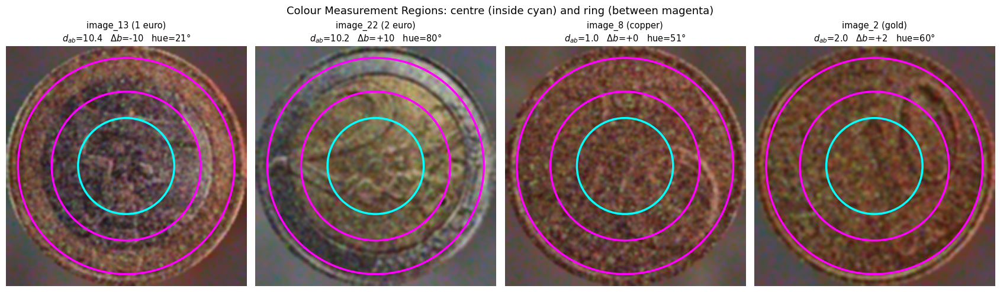

In [11]:
# One representative coin per family, picked from the target set
examples = [("image_13", "1 euro"), ("image_22", "2 euro"), ("image_8", "copper"), ("image_2", "gold")]

fig, axes = plt.subplots(1, 4, figsize=(17, 4.8))
for ax, (scene, kind) in zip(axes, examples):
    img = load_target(TARGET_DIR / f"{scene}.jpg")
    c = detect_coins(img)[0]
    norm = normalize_coin(img, c)
    f = color_features(norm)

    ax.imshow(to_rgb(norm))
    centre = (NORM_SIZE / 2 - 0.5, NORM_SIZE / 2 - 0.5)
    ax.add_patch(plt.Circle(centre, COLOR_RADII["center"] * NORM_SIZE / 2, fill=False, ec="cyan", lw=2.5))
    for rho in (COLOR_RADII["ring_in"], COLOR_RADII["ring_out"]):
        ax.add_patch(plt.Circle(centre, rho * NORM_SIZE / 2, fill=False, ec="magenta", lw=2.5))
    ax.set_title(f"{scene} ({kind})\n$d_{{ab}}$={f['dab']:.1f}   $\\Delta b$={f['db']:+.0f}   hue={f['hue']:.0f}°",
                 fontsize=10.5)
    ax.axis("off")
plt.suptitle("Colour Measurement Regions: centre (inside cyan) and ring (between magenta)", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

### 6.2 Colour groups with soft confidence

Each feature is turned into a confidence in $[0, 1]$ by a sigmoid $\sigma(x) = 1 / (1 + e^{-x})$ with a **threshold** $T$ and a **width** $W$: inside the band of width $W$ around the threshold the confidence is split between the two outcomes.

$$P(\text{bi}) = \sigma\!\left(\frac{d_{ab} - T_{bi}}{W_{bi}}\right), \qquad P(\text{au} \mid \text{single}) = \sigma\!\left(\frac{h - H_{mid}}{W_h}\right), \qquad P(2€ \mid \text{bi}) = \sigma\!\left(\frac{\Delta b}{W_{\Delta b}}\right)$$

$$P(\text{au}) = (1 - P(\text{bi})) \, P(\text{au} \mid \text{single}), \qquad P(\text{cu}) = (1 - P(\text{bi})) \, (1 - P(\text{au} \mid \text{single}))$$

This can be read as a two-level tree with soft branches: the first split is bimetallic vs single alloy, and only what is left to the single-alloy branch is divided between gold and copper. The family with the largest value is the **colour verdict** for the coin. The code works with logarithms of these confidences, which are added to the descriptor and size terms of Sections 6.4 and 6.5.

**All five parameters are taken from the 8 reference coins**, so the target images are measured only at run time (Section 7); the few target coins shown in 6.1 and 6.3 are illustrations, and no parameter is computed from them. For this to work, the features should be as insensitive as possible to the lighting of the photo, since references and targets are not shot under the same conditions. Two adjustments to the features of 6.1 go in this direction:

1. **Chroma relative to lightness for $d_{ab}$ and $\Delta b$.** A darker region tends to have a smaller chroma even if the metal is the same: on the 5c reference, whose centre is much darker than its ring, the raw $d_{ab}$ is $6.4$, close to a bimetallic coin. $a^*$ and $b^*$ are therefore divided by $L^*$, the preprocessed lightness of 6.1 (after filtering and CLAHE). This is a heuristic, not an exact shading correction: it brings the 5c reference down to $2.8$. Since $d_{ab}$ and $\Delta b$ compare two regions of the *same* coin, they are less sensitive to the colour of the light than an absolute colour, but not immune to it: a coloured light can still tint one alloy more than the other, as for the warm-lit bimetallic coins that fall below $T_{bi}$ in Section 8.2.
2. **Colour constancy for the hue.** The hue is an absolute colour, and it follows the light: the references are shot under nearly neutral light, while most target scenes are clearly yellower, so a threshold read off the raw references would fall inside the copper coins of the targets. Before measuring the hue, each image is therefore balanced with **Grey-Edge** [1]: assuming that the *differences* of colour between neighbouring surfaces average to grey, the colour of the light is estimated as the Minkowski $p$-norm of the gradient magnitude of each channel, and a diagonal (von Kries) gain maps it to grey. We take $p = 6$, the value Finlayson and Trezzi found best for Shades of Grey [2], and a light smoothing $\sigma = 1$. Neither is tuned for Grey-Edge or for our data: [1] reports different optima on different datasets (for instance $p = 7, \sigma = 4$ on an indoor set and $p = 1, \sigma = 6$ on a real-world set), so both are heuristic defaults. One extra assumption is added: **the coins themselves are left out of the estimate** (a disc of $1.15\,r$ around each detected circle). Copper and gold are coloured metals, so their edges are coloured too, and Grey-Edge would read them as a yellow light and over-correct; the background is the part of the scene for which the grey-edge hypothesis is reasonable. The circles are already known from the detector of Section 4. Unlike White-Patch (6.1), Grey-Edge does not rely on the brightest pixels, although with $p = 6$ the estimate is dominated by the strongest edges.

**From references to parameters.** With one coin per denomination, each split has a smallest gap between the two classes, for instance between the yellowest copper reference and the least yellow gold one. We use the simplest rule that respects it:
- the **threshold** is the midpoint of the gap;
- the **width** is set so that the two references on either side of the gap get a confidence of $90\%$: $W = \tfrac{1}{2}\,\text{gap} / \ln 9$.

The threshold between 1€ and 2€ is kept at $\Delta b = 0$ by symmetry (silver centre in a golden ring, or the opposite); only its width comes from the references.

These **confidences** add up to one and behave like probabilities, but they are not calibrated probabilities: nothing guarantees that, say, the coins with $P(\text{au}) = 0.8$ are gold 80% of the time. The sigmoids are a convenient soft decision rule, not a calibrated model.

In [12]:
GREY_EDGE_P, GREY_EDGE_SIGMA = 6, 1.0
COIN_EXCLUSION = 1.15  # coins (and their rim shadow) are left out of the light estimate
CONF_AT_GAP = 0.9      # confidence given to the references on either side of a gap


def grey_edge_gains(img_bgr: np.ndarray, circles: List[Circle], p: int = GREY_EDGE_P,
                    sigma: float = GREY_EDGE_SIGMA) -> np.ndarray:
    # Light colour = Minkowski p-norm of the gradient magnitude of each channel, measured outside the coins;
    # von Kries gains map it to grey
    im = cv2.GaussianBlur(img_bgr.astype(np.float32), (0, 0), sigma)
    yy, xx = np.ogrid[:img_bgr.shape[0], :img_bgr.shape[1]]
    background = np.ones(img_bgr.shape[:2], bool)
    for c in circles:
        background &= (yy - c.cy) ** 2 + (xx - c.cx) ** 2 > (COIN_EXCLUSION * c.r) ** 2
    e = np.array([np.mean(np.hypot(cv2.Sobel(im[..., ch], cv2.CV_32F, 1, 0),
                                   cv2.Sobel(im[..., ch], cv2.CV_32F, 0, 1))[background] ** p) ** (1 / p)
                  for ch in range(3)])
    e = np.maximum(e, 1e-6)
    return e.mean() / e


def apply_gains(img_bgr: np.ndarray, gains: np.ndarray) -> np.ndarray:
    return np.clip(img_bgr.astype(np.float32) * gains.astype(np.float32), 0, 255).astype(np.uint8)


def lab_planes(img_bgr: np.ndarray, c: Circle) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    # L* (0-100), a*, b* of the normalised coin of Section 6.1, after the same 5x5 median
    lab = cv2.cvtColor(cv2.medianBlur(normalize_coin(img_bgr, c), 5), cv2.COLOR_BGR2LAB).astype(np.float32)
    return lab[..., 0] * 100 / 255, lab[..., 1] - 128, lab[..., 2] - 128


def coin_colour(img_bgr: np.ndarray, img_balanced: np.ndarray, c: Circle) -> Dict[str, float]:
    # d_ab and delta-b: chroma relative to lightness, centre vs ring, on the original image
    L, a, b = lab_planes(img_bgr, c)
    L = np.maximum(L, 5.0)
    a_rel, b_rel = 50 * a / L, 50 * b / L          # 50 = mid-grey lightness, keeps the usual Lab scale
    f = {}
    for region, mask in (("c", MASK_CENTER), ("r", MASK_RING)):
        f[f"a_{region}"], f[f"b_{region}"] = float(np.median(a_rel[mask])), float(np.median(b_rel[mask]))
    f["dab"] = float(np.hypot(f["a_c"] - f["a_r"], f["b_c"] - f["b_r"]))
    f["db"] = f["b_c"] - f["b_r"]
    # hue: centre of the Grey-Edge balanced image
    _, a, b = lab_planes(img_balanced, c)
    f["hue"] = float(np.degrees(np.arctan2(np.median(b[MASK_CENTER]), np.median(a[MASK_CENTER]))))
    return f


def measure_colour(img_bgr: np.ndarray, circles: List[Circle]) -> List[Dict[str, float]]:
    # One light estimate per image, shared by all its coins
    balanced = apply_gains(img_bgr, grey_edge_gains(img_bgr, circles))
    return [coin_colour(img_bgr, balanced, c) for c in circles]


def sigmoid(x: float) -> float:
    return 1.0 / (1.0 + np.exp(-x))


def log_sigmoid(x: float) -> float:
    # log(sigmoid(x)), numerically stable
    return float(-np.logaddexp(0.0, -x))


def colour_confidences(f: Dict[str, float], p: Dict[str, float]) -> dict:
    # Soft two-level tree (bimetallic or not, then gold vs copper) plus 2 euro vs 1 euro, in log space
    x_bi = (f["dab"] - p["T_BI"]) / p["W_BI"]
    x_au = (f["hue"] - p["H_MID"]) / p["W_H"]
    x_2e = f["db"] / p["W_DB"]
    log = {"bi": log_sigmoid(x_bi),
           "au": log_sigmoid(-x_bi) + log_sigmoid(x_au),
           "cu": log_sigmoid(-x_bi) + log_sigmoid(-x_au)}
    log["2euro"] = log["bi"] + log_sigmoid(x_2e)
    log["1euro"] = log["bi"] + log_sigmoid(-x_2e)
    P = {g: float(np.exp(log[g])) for g in ("cu", "au", "bi")}
    P["log"] = log
    return P

**The colour features of the references, and the parameters derived from them.** The table lists the three features of each reference coin; the bar charts show them with the thresholds (dashed) and the band of one width on either side (shaded).

In [13]:
REF_COLOUR = pd.DataFrame({label: measure_colour(ref_images[label], [ref_circles[label]])[0]
                           for label in DENOMINATIONS}).T.astype(float)
K_GAP = np.log(CONF_AT_GAP / (1 - CONF_AT_GAP))   # ln 9


def gap_rule(lower: pd.Series, upper: pd.Series) -> Tuple[float, float]:
    # threshold = midpoint of the gap between the two classes, width = half gap / ln 9
    lo, hi = float(lower.max()), float(upper.min())
    assert hi > lo, "the reference classes overlap"
    return float((lo + hi) / 2), float((hi - lo) / 2 / K_GAP)


single_alloy = GROUPS["cu"] + GROUPS["au"]
T_BI, W_BI = gap_rule(REF_COLOUR.dab[single_alloy], REF_COLOUR.dab[GROUPS["bi"]])
H_MID, W_H = gap_rule(REF_COLOUR.hue[GROUPS["cu"]], REF_COLOUR.hue[GROUPS["au"]])
_, W_DB = gap_rule(REF_COLOUR.db[["1euro"]], REF_COLOUR.db[["2euro"]])
COLOUR_PARAMS = dict(T_BI=T_BI, W_BI=W_BI, H_MID=H_MID, W_H=W_H, W_DB=W_DB)
print("Colour parameters from the references:", {k: round(v, 2) for k, v in COLOUR_PARAMS.items()})
dab_5c_raw = color_features(normalize_coin(ref_images["5cent"], ref_circles["5cent"]))["dab"]
print(f"5c reference: d_ab = {dab_5c_raw:.1f} with the plain features of 6.1, "
      f"{REF_COLOUR.dab['5cent']:.1f} with chroma relative to lightness")

table = REF_COLOUR[["dab", "hue", "db"]].round(1)
table.insert(0, "family", [GROUP_NAMES[GROUP_OF[label]] for label in table.index])
table

Colour parameters from the references: {'T_BI': 9.12, 'W_BI': 2.52, 'H_MID': 49.73, 'W_H': 2.99, 'W_DB': 6.87}
5c reference: d_ab = 6.4 with the plain features of 6.1, 2.8 with chroma relative to lightness


,family,dab,hue,db
1cent,copper,1.3,40.8,1.2
2cent,copper,1.5,43.2,-1.3
5cent,copper,2.8,35.0,0.9
10cent,gold,0.5,56.3,-0.0
20cent,gold,1.2,57.7,-0.9
50cent,gold,3.6,59.0,1.9
1euro,bimetallic,16.4,36.9,-15.6
2euro,bimetallic,14.7,77.5,14.5


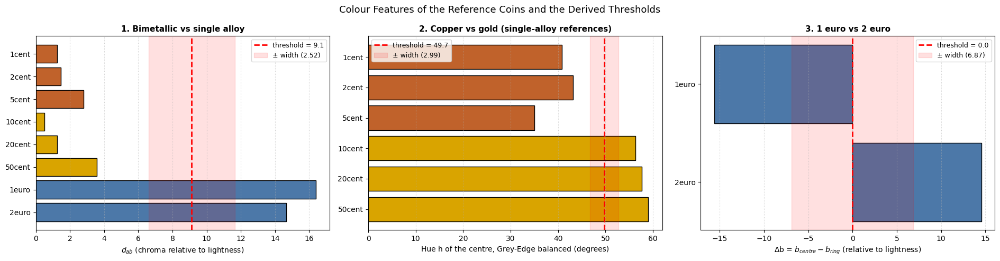

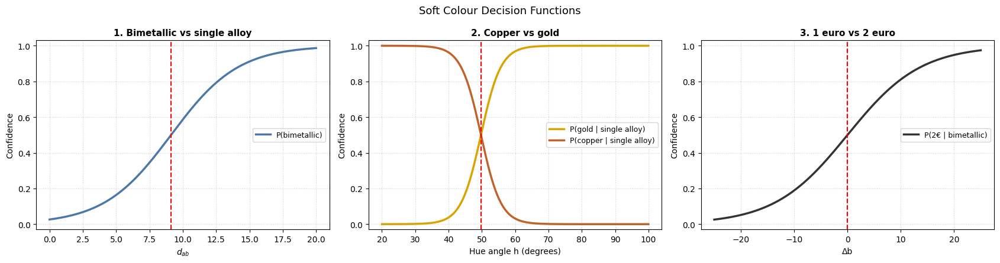

In [14]:
p = COLOUR_PARAMS
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
panels = [("dab", "$d_{ab}$ (chroma relative to lightness)", p["T_BI"], p["W_BI"], DENOMINATIONS),
          ("hue", "Hue h of the centre, Grey-Edge balanced (degrees)", p["H_MID"], p["W_H"], single_alloy),
          ("db", "Δb = $b_{centre} - b_{ring}$ (relative to lightness)", 0.0, p["W_DB"], GROUPS["bi"])]
for ax, (feat, xlabel, thr, width, labels) in zip(axes, panels):
    ax.barh(labels, REF_COLOUR.loc[labels, feat], color=[GROUP_COLORS[GROUP_OF[l]] for l in labels], edgecolor="black")
    ax.axvline(thr, color="red", ls="--", lw=2, label=f"threshold = {thr:.1f}")
    ax.axvspan(thr - width, thr + width, color="red", alpha=0.12, label=f"± width ({width:.2f})")
    ax.set_xlabel(xlabel)
    ax.invert_yaxis()
    ax.grid(True, axis="x", ls=":", alpha=0.6)
    ax.legend(fontsize=9)
axes[0].set_title("1. Bimetallic vs single alloy", fontsize=11, fontweight="bold")
axes[1].set_title("2. Copper vs gold (single-alloy references)", fontsize=11, fontweight="bold")
axes[2].set_title("3. 1 euro vs 2 euro", fontsize=11, fontweight="bold")
plt.suptitle("Colour Features of the Reference Coins and the Derived Thresholds", fontsize=13)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
x = np.linspace(0, 20, 300)
axes[0].plot(x, sigmoid((x - p["T_BI"]) / p["W_BI"]), color=GROUP_COLORS["bi"], lw=2.5, label="P(bimetallic)")
axes[0].axvline(p["T_BI"], color="red", ls="--")
axes[0].set_xlabel("$d_{ab}$")
axes[0].set_title("1. Bimetallic vs single alloy", fontsize=11, fontweight="bold")

x = np.linspace(20, 100, 300)
pau = sigmoid((x - p["H_MID"]) / p["W_H"])
axes[1].plot(x, pau, color=GROUP_COLORS["au"], lw=2.5, label="P(gold | single alloy)")
axes[1].plot(x, 1 - pau, color=GROUP_COLORS["cu"], lw=2.5, label="P(copper | single alloy)")
axes[1].axvline(p["H_MID"], color="red", ls="--")
axes[1].set_xlabel("Hue angle h (degrees)")
axes[1].set_title("2. Copper vs gold", fontsize=11, fontweight="bold")

x = np.linspace(-25, 25, 300)
axes[2].plot(x, sigmoid(x / p["W_DB"]), color="#333333", lw=2.5, label="P(2€ | bimetallic)")
axes[2].axvline(0, color="red", ls="--")
axes[2].set_xlabel("Δb")
axes[2].set_title("3. 1 euro vs 2 euro", fontsize=11, fontweight="bold")
for ax in axes:
    ax.set_ylabel("Confidence")
    ax.set_ylim(-0.03, 1.03)
    ax.grid(True, ls=":", alpha=0.6)
    ax.legend(loc="center right", fontsize=9)
plt.suptitle("Soft Colour Decision Functions", fontsize=13)
plt.tight_layout()
plt.show()

### 6.3 Matching against the templates

Each detected coin goes through `coin_to_polar`, exactly like the references, and `polar_distances` gives its distance from the 8 templates (for the target set, at run time in Section 7). The figure takes one target coin apart: its descriptor rotated by the best shift, the closest template, the correlation as a function of the rotation, and the eight distances. The height of a correlation peak says *how similar* the coin is, its position *at which orientation*.

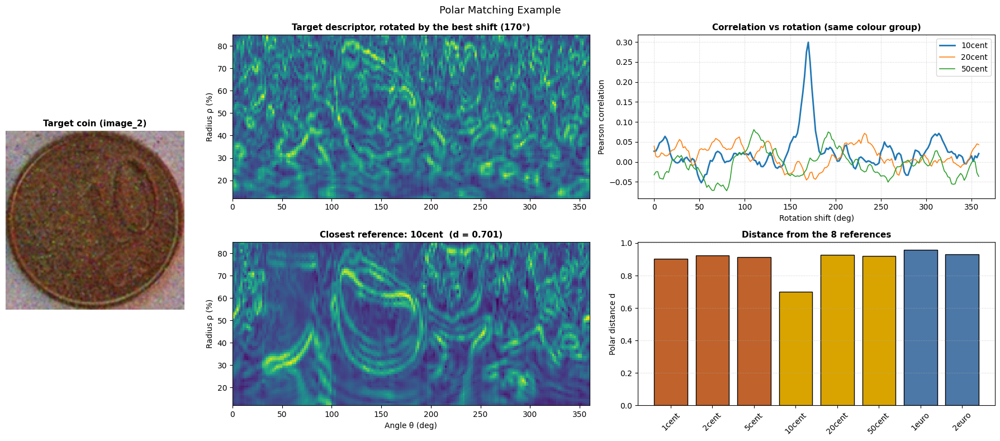

In [15]:
img = load_target(TARGET_DIR / "image_2.jpg")
c = detect_coins(img)[0]
crop = crop_coin(img, c)
tgt = coin_to_polar(crop)
dists = polar_distances(img, c)
best = min(dists, key=dists.get)
shift = int(np.argmax(circular_correlation(REF_POLARS[best], tgt)))

fig = plt.figure(figsize=(18, 8))
gs = fig.add_gridspec(2, 3, width_ratios=[0.8, 1.6, 1.6])
ax = fig.add_subplot(gs[:, 0])
ax.imshow(to_rgb(crop))
ax.set_title("Target coin (image_2)", fontsize=11, fontweight="bold")
ax.axis("off")

ax = fig.add_subplot(gs[0, 1])
ax.imshow(np.roll(tgt, shift, axis=0).T, aspect="auto", cmap="viridis", origin="lower", extent=[0, 360, 12, 85])
ax.set_title(f"Target descriptor, rotated by the best shift ({2 * shift}°)", fontsize=11, fontweight="bold")
ax.set_ylabel("Radius ρ (%)")
ax = fig.add_subplot(gs[1, 1])
ax.imshow(REF_POLARS[best].T, aspect="auto", cmap="viridis", origin="lower", extent=[0, 360, 12, 85])
ax.set_title(f"Closest reference: {best}  (d = {dists[best]:.3f})", fontsize=11, fontweight="bold")
ax.set_xlabel("Angle θ (deg)")
ax.set_ylabel("Radius ρ (%)")

ax = fig.add_subplot(gs[0, 2])
for label in GROUPS[GROUP_OF[best]]:
    ax.plot(np.arange(POLAR_ANGULAR_SAMPLES) * 2, circular_correlation(REF_POLARS[label], tgt),
            lw=2 if label == best else 1.2, label=label)
ax.set_xlabel("Rotation shift (deg)")
ax.set_ylabel("Pearson correlation")
ax.set_title("Correlation vs rotation (same colour group)", fontsize=11, fontweight="bold")
ax.grid(True, ls=":", alpha=0.6)
ax.legend()

ax = fig.add_subplot(gs[1, 2])
ax.bar(DENOMINATIONS, [dists[l] for l in DENOMINATIONS],
       color=[GROUP_COLORS[GROUP_OF[l]] for l in DENOMINATIONS], edgecolor="black")
ax.set_ylabel("Polar distance d")
ax.set_title("Distance from the 8 references", fontsize=11, fontweight="bold")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, axis="y", ls=":", alpha=0.6)
plt.suptitle("Polar Matching Example", fontsize=13)
plt.tight_layout()
plt.show()

### 6.4 Combining colour and descriptor: the temperature $\tau$

The descriptor gives distances, the colour step gives confidences. To put them on the same scale, the distances are turned into scores with a decaying exponential:

$$P(\ell \mid \text{descriptor}) \propto \exp\!\left(-\frac{d_\ell}{\tau}\right)$$

and the log-scores of the two cues are added. Adding logarithms treats the cues as independent pieces of evidence. This is a simplification: it is plausible here, since colour reads the chroma of two regions and the descriptor reads the gradient structure of the luminance, but it also means that one very confident cue can overrule the other. In logarithms, every denomination $\ell$ of family $g(\ell)$ gets the score

$$\log S(\ell) = \begin{cases} \log P\big(g(\ell)\big) - \dfrac{d_\ell - d_{\min}}{\tau} & \ell \in \{\text{1c}, \dots, \text{50c}\} \\[2ex] \log P(\text{bi}) + \log \sigma\!\left(\pm \dfrac{\Delta b}{W_{\Delta b}}\right) - \dfrac{d_{bi} - d_{\min}}{\tau} & \ell \in \{1€ \,(-),\ 2€ \,(+)\} \end{cases}$$

and the highest score wins ($d_{\min}$, the smallest distance of the coin, is common to all candidates and only keeps the numbers small). For 1€ and 2€ the descriptor only says "bimetallic": both use $d_{bi} = \min(d_{1€}, d_{2€})$, and the extra term $\log \sigma(\pm \Delta b / W_{\Delta b})$ splits the bimetallic confidence between 1€ and 2€ according to the sign of $\Delta b$.

**Choice of $\tau$:** it plays the role of a temperature: it is the exchange rate between the two cues, since a distance difference of $\tau$ is worth one unit of log-confidence (a factor $e$). With $\tau \to 0$ the nearest template always wins and colour is ignored; with $\tau \to \infty$ the descriptor is ignored. The natural scale is the **typical separation between the two most similar competing templates**, and it can be read off the reference bank alone. A real coin is never close to its own template (worn metal, different lighting), so the decision is a competition among templates that all look like "another coin". The distance matrix of Section 5.3 shows exactly this situation: each reference against the seven *other* templates. For each reference we take the gap between its two closest other templates, $\Delta = d_{(2)} - d_{(1)}$, and set $\tau$ to the median of the eight gaps. With this choice:
- for a coin with a typical margin, the descriptor favours its best template with odds $e:1$, i.e. $\sigma(1) \approx 0.73$ in a two-way choice, the same weight as a colour confidence one width $W$ away from its threshold, so neither cue dominates by default;
- a clear match (margin of several $\tau$) overrides an uncertain colour, while a thin margin hands the decision over to colour.

The median is chosen rather than the mean because with only eight values, a single large gap would pull the mean.

In [ ]:
# Gap between the two closest OTHER templates of each reference (distance matrix of Section 5.3)
ref_gaps = pd.Series({label: float(np.diff(np.sort(np.delete(ref_dist[i], i))[:2])[0])
                      for i, label in enumerate(DENOMINATIONS)})
TAU = float(ref_gaps.median())
print(f"tau = median gap between the two closest other templates = {TAU:.3f}   (mean {ref_gaps.mean():.3f})")

tau = median gap between the two closest other templates = 0.023   (mean 0.031)


### 6.5 Relative size: the weight $\lambda$

Within copper and within gold, what really separates the three denominations is the diameter, which the scale-normalised descriptor cannot see; for 1€ and 2€ it is one more piece of evidence. Coins in the same picture share the same scale $s$ (pixels per mm), so a candidate $\ell$ for a coin of radius $r$ has a log-size error

$$e_\ell = \left| \log \frac{r}{s \, D_\ell} \right|$$

and its score becomes $\log S(\ell) - \lambda\, e_\ell$. The classification runs twice:
1. a **first pass** with colour and descriptor only; the scene scale is estimated as $\hat s = \operatorname{median}(r) / \operatorname{median}(D_{\hat\ell})$ from the first-pass labels (with three or more coins the medians are robust to one wrong first-pass label; with two coins the median is just the mean, so a single wrong label shifts the scale);
2. a **second pass** that adds $-\lambda e_\ell$ to every candidate, all eight denominations alike, and picks again.

The size term is switched off when a scene holds a single coin, since there is nothing to compare it with.

**Choice of $\lambda$:** The penalty $-\lambda e_\ell$ is linear in the log-size error. Two choices are behind it:
- *logarithms*, because size errors are multiplicative: the scale changes with the camera distance, and a few pixels of error weigh more on a small coin than on a large one;
- *linear rather than quadratic*, so that an occasional badly estimated radius (shadow, touching coin) is not punished out of proportion.

Within a colour family the two closest diameters are 20c and 50c ($22.25$ and $24.25$ mm, a log ratio of $0.086$). We require that a coin exactly halfway between them ($e = 0.043$ from both) costs each candidate a factor $2$ with respect to a perfectly sized one, which gives $\lambda = \ln 2 \,/\, 0.043 \approx 16$ (the factor $2$ is a heuristic choice):

$$\lambda = \frac{\ln 2}{\tfrac{1}{2} \ln \frac{24.25}{22.25}} \approx 16$$

Consequences: a coin of exactly the 20c size makes the 50c hypothesis $e^{-\lambda \cdot 0.086} \approx 4$ times less likely, and the separation is stronger for the other pairs (about $10$ times for 1c vs 2c). $1/\lambda \approx 6\%$ is also of the same order as the expected error on the relative radius: a few pixels on radii of $50$–$120$ px ($2$–$5\%$), plus the error of the scene scale.

The chart shows why size is applied *after* colour rather than used alone: inside each family the diameters are well spaced, but across families they interleave (10c, for instance, falls between 2c and 5c).

lambda = 16.1


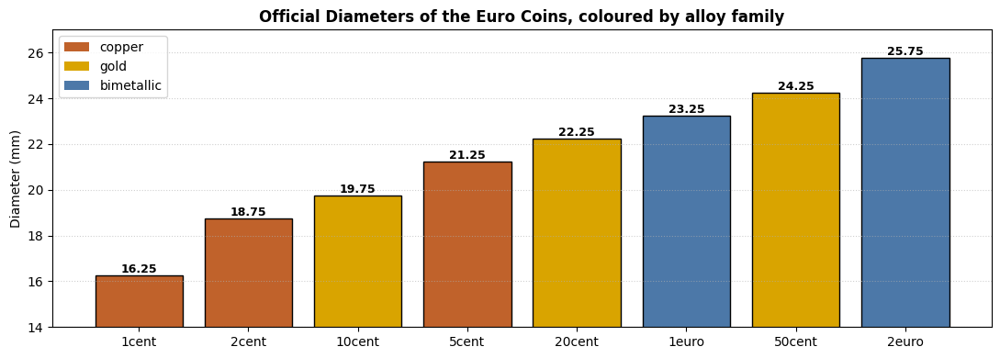

In [17]:
SIZE_WEIGHT = float(np.log(2) / (0.5 * np.log(COIN_DIAMETERS["50cent"] / COIN_DIAMETERS["20cent"])))
PARAMS = {**COLOUR_PARAMS, "TAU": TAU, "SIZE_WEIGHT": SIZE_WEIGHT}
print(f"lambda = {SIZE_WEIGHT:.1f}")


def candidate_log_scores(coin: dict, params: dict, scale: Optional[float] = None) -> Dict[str, float]:
    # log S(l) = log P(family) [+ log sigma(+-db / W_db) for 1 and 2 euro] - (d_l - d_min) / tau  [- lambda * size error]
    log_p, D = coin["P"]["log"], coin["dist"]
    d_min = min(D.values())
    d_bi = min(D["1euro"], D["2euro"])
    scores = {}
    for label in DENOMINATIONS:
        g = GROUP_OF[label]
        prior, d = (log_p[label], d_bi) if g == "bi" else (log_p[g], D[label])
        s = prior - (d - d_min) / params["TAU"]
        if scale is not None:   # every candidate, bimetallic ones included
            s -= params["SIZE_WEIGHT"] * abs(np.log(coin["circle"].r / (scale * COIN_DIAMETERS[label])))
        scores[label] = s
    return scores


def best_label(scores: Dict[str, float]) -> str:
    return max(scores, key=scores.get)


def classify_scene(coins: List[dict], params: dict) -> Tuple[List[str], List[str]]:
    # (first-pass labels, final labels)
    first = [best_label(candidate_log_scores(c, params)) for c in coins]
    if len(coins) < 2:
        return first, first
    scale = np.median([c["circle"].r for c in coins]) / np.median([COIN_DIAMETERS[l] for l in first])
    return first, [best_label(candidate_log_scores(c, params, scale)) for c in coins]


order = sorted(DENOMINATIONS, key=COIN_DIAMETERS.get)
fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(order, [COIN_DIAMETERS[l] for l in order], color=[GROUP_COLORS[GROUP_OF[l]] for l in order],
              edgecolor="black")
ax.bar_label(bars, labels=[f"{COIN_DIAMETERS[l]:.2f}" for l in order], fontsize=9, fontweight="bold")
for g, col in GROUP_COLORS.items():
    ax.bar(0, 0, color=col, label=GROUP_NAMES[g])
ax.set_ylim(14, 27)
ax.set_ylabel("Diameter (mm)")
ax.set_title("Official Diameters of the Euro Coins, coloured by alloy family", fontsize=12, fontweight="bold")
ax.legend()
ax.grid(True, axis="y", ls=":", alpha=0.6)
plt.tight_layout()
plt.show()

## 7. Running the Pipeline

The target images are measured only here, at run time: `extract_scene` detects the coins of one image and measures them (colour, with the Grey-Edge balance of that image, and polar distances from the templates), `predict_scene` labels them with the parameters of Section 6, and `analyse_scene` chains the two. The `refine` switch, on by default, is only turned off by the ablation of Section 8.4. Every intermediate result (circles, colour features, confidences, polar distances, first-pass label) stays attached to each coin, so Section 8 can inspect it.

In [ ]:
def extract_scene(img_bgr: np.ndarray, refine: bool = True) -> List[dict]:
    # Detection + colour features + polar distances of every coin of one image
    # (refine=False keeps the raw Hough circles: used only by the ablation of Section 8.4)
    refined, raw = detect_coins(img_bgr, return_raw=True)
    circles = refined if refine else raw
    colours = measure_colour(img_bgr, circles)
    return [{"circle": c, "hough": h, "features": f, "dist": polar_distances(img_bgr, c)}
            for c, h, f in zip(circles, raw, colours)]


def predict_scene(coins: List[dict], params: dict = PARAMS) -> List[dict]:
    out = [{**coin, "P": colour_confidences(coin["features"], params)} for coin in coins]
    first, final = classify_scene(out, params)
    for coin, a, b in zip(out, first, final):
        coin["label_pass1"], coin["label"] = a, b
    return out


def analyse_scene(img_bgr: np.ndarray, params: dict = PARAMS, refine: bool = True) -> List[dict]:
    # Image in, labelled coins out
    return predict_scene(extract_scene(img_bgr, refine), params)


def scene_cents(coins: List[dict]) -> int:
    return int(sum(VALUE_CENTS[coin["label"]] for coin in coins))


def draw_scene(ax, img_bgr: np.ndarray, coins: List[dict], title: str):
    # Circle plus a label badge coloured by alloy family
    ax.imshow(to_rgb(img_bgr))
    for coin in coins:
        c, label = coin["circle"], coin["label"]
        ax.add_patch(plt.Circle((c.cx, c.cy), c.r, fill=False, ec="lime", lw=2.5))
        ax.text(c.cx, c.cy - c.r - 12, label, color="black", fontsize=10, fontweight="bold", ha="center",
                bbox=dict(boxstyle="round,pad=0.2", fc=GROUP_COLORS[GROUP_OF[label]], alpha=0.9, lw=0))
    ax.set_title(f"{title} - {len(coins)} coin(s) | Total: {scene_cents(coins) / 100:.2f} EUR", fontsize=11, fontweight="bold")
    ax.axis("off")

### 7.1 A few scenes, visually

Six target images: each coin is circled and tagged with its predicted denomination (tag colour = alloy family), and the title reports the total of the image. The six scenes were picked among those that the evaluation of Section 8 finds entirely correct (image_118 holds all eight denominations), so they show the pipeline when it works.

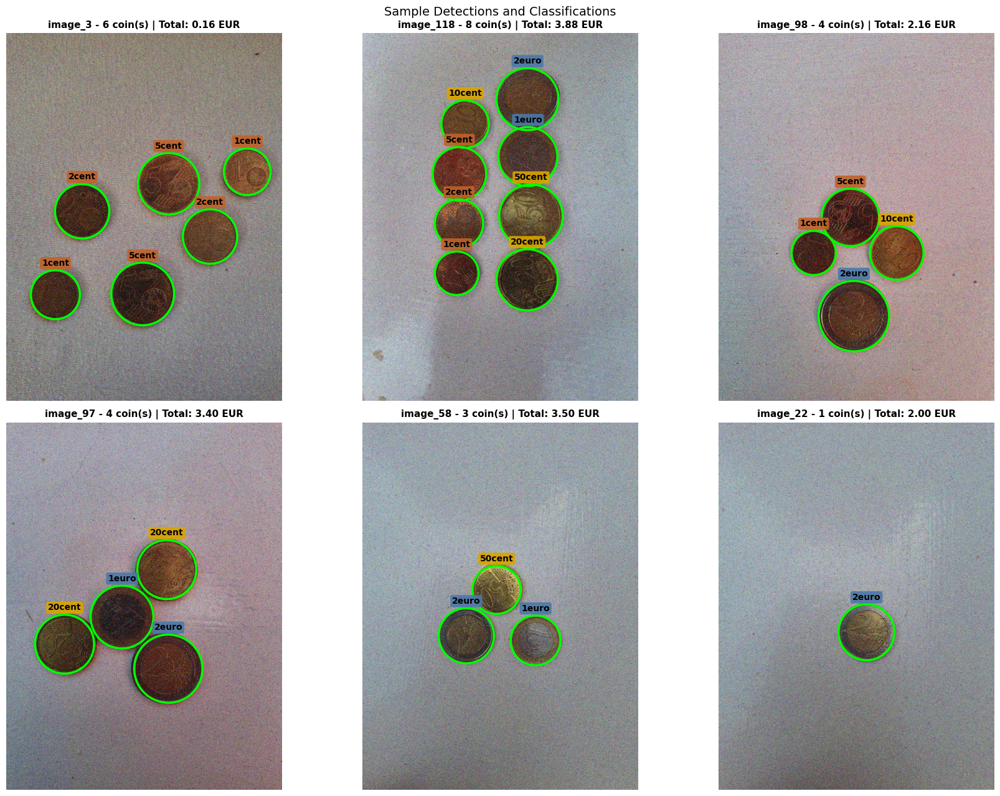

In [19]:
sample_names = ["image_3", "image_118", "image_98", "image_97", "image_58", "image_22"]
fig, axes = plt.subplots(2, 3, figsize=(18, 13))
for ax, name in zip(axes.flatten(), sample_names):
    img = load_target(TARGET_DIR / f"{name}.jpg")
    draw_scene(ax, img, analyse_scene(img), name)
plt.suptitle("Sample Detections and Classifications", fontsize=14)
plt.tight_layout()
plt.show()

### 7.2 Whole target set: required output

Every target image is classified and the result is printed in the format requested by the assignment: the value of each coin, the partial amount of each image and the overall amount.

In [20]:
results: Dict[str, List[dict]] = {}
grand_total_cents = 0
print(f"Classifying {len(target_paths)} target images\n")

for path in target_paths:
    coins = analyse_scene(load_target(path))
    results[path.stem] = coins

    print(f"{path.name} - {len(coins)} coin(s) found:")
    partial_cents = 0
    for j, coin in enumerate(coins, 1):
        cents = VALUE_CENTS[coin["label"]]
        partial_cents += cents
        print(f"  Coin {j} {{value: {cents / 100:.3f}}}")
    print(f"  Partial Amount {{value: {partial_cents / 100:.3f}}}")
    grand_total_cents += partial_cents

print("\n" + "-" * 42)
print(f"Total Amount: {grand_total_cents / 100:.2f} €")
print("-" * 42)

Classifying 142 target images

image_1.jpg - 3 coin(s) found:
  Coin 1 {value: 0.050}
  Coin 2 {value: 0.050}
  Coin 3 {value: 0.020}
  Partial Amount {value: 0.120}
image_2.jpg - 1 coin(s) found:
  Coin 1 {value: 0.100}
  Partial Amount {value: 0.100}
image_3.jpg - 6 coin(s) found:
  Coin 1 {value: 0.050}
  Coin 2 {value: 0.050}
  Coin 3 {value: 0.010}
  Coin 4 {value: 0.020}
  Coin 5 {value: 0.020}
  Coin 6 {value: 0.010}
  Partial Amount {value: 0.160}
image_4.jpg - 1 coin(s) found:
  Coin 1 {value: 0.010}
  Partial Amount {value: 0.010}
image_5.jpg - 1 coin(s) found:
  Coin 1 {value: 0.100}
  Partial Amount {value: 0.100}
image_6.jpg - 1 coin(s) found:
  Coin 1 {value: 0.200}
  Partial Amount {value: 0.200}
image_7.jpg - 3 coin(s) found:
  Coin 1 {value: 0.050}
  Coin 2 {value: 0.500}
  Coin 3 {value: 0.500}
  Partial Amount {value: 1.050}
image_8.jpg - 1 coin(s) found:
  Coin 1 {value: 0.020}
  Partial Amount {value: 0.020}
image_9.jpg - 1 coin(s) found:
  Coin 1 {value: 0.020}
  

### 7.3 Optional: every scene, visually

Set `SHOW_ALL` to `True` to draw circles and labels on all the target images, four per row.

In [ ]:
SHOW_ALL = False

if SHOW_ALL:
    for k in range(0, len(target_paths), 4):
        batch = target_paths[k:k + 4]
        fig, axes = plt.subplots(1, 4, figsize=(20, 6))
        for ax in axes:
            ax.axis("off")
        for ax, path in zip(axes, batch):
            draw_scene(ax, load_target(path), results[path.stem], path.stem)
        plt.tight_layout()
        plt.show()

## 8. Evaluation

The target set was annotated by hand, recording the centre and the denomination of every coin (`coin_annotations.csv`). The file is read **only in this section**. Coins that could not be identified with confidence (heavily occluded or blurred) are labelled `unk`.

**Matching detections to annotations.** One-to-one assignment (Hungarian algorithm) on the centre distance, accepting a pair only if the annotated centre lies within $0.6\,r$ of the detected one. A matched circle is a hit, an unmatched circle is spurious, an unmatched annotation is a miss; circles on `unk` coins count neither way.

**Metrics.**
- *Detection*: precision, recall, F1.
- *Classification*, on the matched coins: accuracy of the alloy family (colour verdict alone and final label) and of the denomination.
- *Money*, on the images without `unk` coins (so that predicted and annotated amounts refer to the same coins): share of images with the exact amount and mean absolute error per image.

The analysis that follows looks at where the errors are (8.1), at the colour features against the true labels (8.2), and at what each cue (8.3) and the circle correction (8.4) contribute.

In [22]:
ASSOC_TOL = 0.6  # a match must lie within 0.6 r of the detected centre

ann = pd.read_csv(ANN_CSV)
SCENES_WITH_UNK = set(ann.scene[ann.label == "unk"])
print(f"Ground truth: {len(ann)} annotated coins over {ann.scene.nunique()} images, "
      f"{(ann.label == 'unk').sum()} of them 'unk' (in {len(SCENES_WITH_UNK)} images)")


def associate(circles: List[Circle], gt: pd.DataFrame) -> List[Optional[int]]:
    # Hungarian matching on centre distance / r; pairs beyond ASSOC_TOL are forbidden
    match = [None] * len(circles)
    if not circles or gt.empty:
        return match
    big = 1e9
    cost = np.full((len(circles), len(gt)), big)
    for i, c in enumerate(circles):
        d = np.hypot(c.cx - gt.cx.to_numpy(), c.cy - gt.cy.to_numpy())
        cost[i] = np.where(d <= ASSOC_TOL * c.r, d / c.r, big)
    for i, j in zip(*linear_sum_assignment(cost)):
        if cost[i, j] < big:
            match[i] = int(j)
    return match


n_known = int((ann.label != "unk").sum())


def evaluate_results(results: Dict[str, List[dict]]):
    # Per-coin table (DET), per-image table (SCENES), matched coins (TP) and summary metrics (M)
    rows, scene_rows, n_missed = [], [], 0
    for scene, coins in results.items():
        gt = ann[ann.scene == scene].reset_index(drop=True)
        match = associate([c["circle"] for c in coins], gt)
        for coin, j in zip(coins, match):
            rows.append({"scene": scene, "n_detected": len(coins), "true": gt.label[j] if j is not None else None,
                         "pred": coin["label"], "pred_pass1": coin["label_pass1"],
                         "colour_group": max(("cu", "au", "bi"), key=coin["P"].get),
                         **{k: coin["features"][k] for k in ("dab", "db", "hue")}, "coin": coin})
        matched = {j for j in match if j is not None}
        n_missed += sum(1 for j in range(len(gt)) if j not in matched and gt.label[j] != "unk")
        known = gt[gt.label != "unk"]
        scene_rows.append({"scene": scene, "n_gt": len(known), "has_unk": scene in SCENES_WITH_UNK,
                           "gt_cents": int(known.label.map(VALUE_CENTS).sum()), "pred_cents": scene_cents(coins)})

    DET, SCENES = pd.DataFrame(rows), pd.DataFrame(scene_rows)
    TP = DET[DET.true.notna() & (DET.true != "unk")].copy()
    TP["true_group"] = TP.true.map(GROUP_OF)
    TP["final_group"] = TP.pred.map(GROUP_OF)
    n_fp = int(DET.true.isna().sum())
    precision, recall = len(TP) / (len(TP) + n_fp), len(TP) / n_known
    full = SCENES[~SCENES.has_unk]
    err = full.pred_cents - full.gt_cents
    M = {"matched": len(TP), "spurious": n_fp, "missed": n_missed,
         "precision": precision, "recall": recall, "F1": 2 * precision * recall / (precision + recall),
         "family_colour": (TP.colour_group == TP.true_group).mean(), "family_final": (TP.final_group == TP.true_group).mean(),
         "polar_only": np.mean([min(c["dist"], key=c["dist"].get) == t for c, t in zip(TP.coin, TP.true)]),
         "denomination": (TP.pred == TP.true).mean(), "n_correct": int((TP.pred == TP.true).sum()),
         "n_full": len(full), "n_exact": int((err == 0).sum()), "exact": (err == 0).mean(),
         "mae_eur": err.abs().mean() / 100, "abs_sum_eur": err.abs().sum() / 100, "signed_sum_eur": err.sum() / 100,
         "pred_total_eur": full.pred_cents.sum() / 100, "gt_total_eur": full.gt_cents.sum() / 100}
    return DET, SCENES, TP, M


DET, SCENES, TP, M = evaluate_results(results)

pct = lambda x: f"{x * 100:.1f}%"
print("\nDETECTION")
print(f"  matched / spurious / missed : {M['matched']} / {M['spurious']} / {M['missed']}   (known coins: {n_known})")
print(f"  precision | recall | F1     : {pct(M['precision'])} | {pct(M['recall'])} | {pct(M['F1'])}")
print(f"CLASSIFICATION ({M['matched']} matched coins)")
print(f"  family, colour alone        : {pct(M['family_colour'])}")
print(f"  family, final label         : {pct(M['family_final'])}")
print(f"  denomination                : {pct(M['denomination'])}  ({M['n_correct']}/{M['matched']})")
print(f"MONEY ({M['n_full']} images without 'unk' coins)")
print(f"  images with the exact amount: {M['n_exact']}/{M['n_full']}  ({pct(M['exact'])})")
print(f"  mean absolute error / image : {M['mae_eur']:.3f} EUR")
print(f"  total predicted vs annotated: {M['pred_total_eur']:.2f} EUR vs {M['gt_total_eur']:.2f} EUR")
print(f"  per-image errors, absolute vs signed sum: {M['abs_sum_eur']:.2f} vs {M['signed_sum_eur']:.2f} EUR")

Ground truth: 328 annotated coins over 142 images, 16 of them 'unk' (in 15 images)

DETECTION
  matched / spurious / missed : 305 / 5 / 7   (known coins: 312)
  precision | recall | F1     : 98.4% | 97.8% | 98.1%
CLASSIFICATION (305 matched coins)
  family, colour alone        : 80.7%
  family, final label         : 94.1%
  denomination                : 82.6%  (252/305)
MONEY (127 images without 'unk' coins)
  images with the exact amount: 84/127  (66.1%)
  mean absolute error / image : 0.097 EUR
  total predicted vs annotated: 121.77 EUR vs 127.98 EUR
  per-image errors, absolute vs signed sum: 12.27 vs -6.21 EUR


### 8.1 Where the mistakes are: confusion matrices

Row-normalised matrices on the matched coins: on the left the colour verdict alone, on the right the final denomination.

Two things stand out. **(i)** 1€ and 2€ are swapped only once, so the sign of $\Delta b$ does its job; and while only $69\%$ of the bimetallic coins get "bimetallic" as colour verdict, $91\%$ of them end up in the right family: many coins with an ambiguous colour are brought back by the descriptor and the size check, which is what the soft fusion is for. **(ii)** Of the $53$ wrong labels, $35$ stay *inside* the right family, between coins of the same alloy and similar diameter (e.g. 2c taken for 1c or 5c), and $18$ cross families, mostly copper coins taken for gold ($10$) and bimetallic coins taken for gold ($6$). Overall the family of the final label is right for $94.1\%$ of the coins, against $80.7\%$ for colour alone: the colour thresholds come from only eight reference photos, and the descriptor and the size check recover most of what they miss.

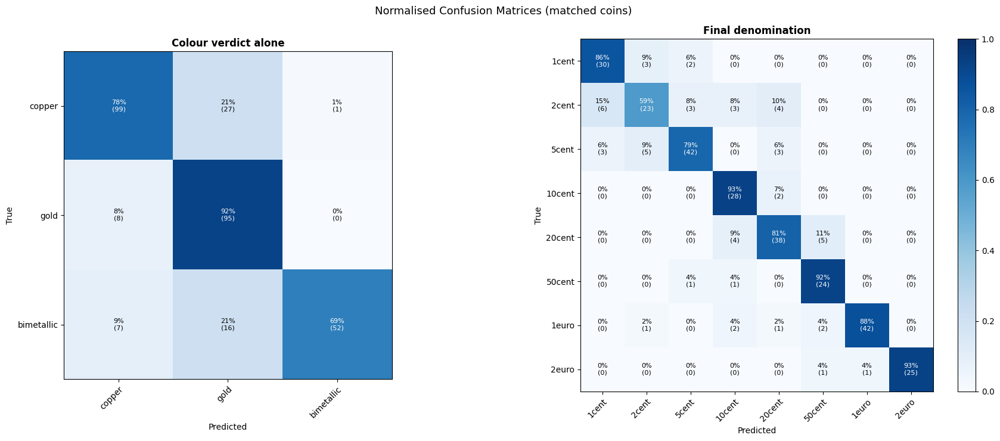

Bimetallic coins: colour verdict 'bimetallic' 69.3%, final family right 90.7%, 1 euro <-> 2 euro swaps 1
Cross-family errors (true family -> predicted family): {('au', 'cu'): 1, ('bi', 'au'): 6, ('bi', 'cu'): 1, ('cu', 'au'): 10}
Errors of the final label: 53, of which 35 inside the right family and 18 across families


In [23]:
def plot_confusion(ax, y_true, y_pred, labels, title, names=None):
    # Each row sums to 100%; raw counts in brackets
    cm = pd.crosstab(pd.Categorical(y_true, labels), pd.Categorical(y_pred, labels), dropna=False).to_numpy()
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    im = ax.imshow(cm_norm, cmap=plt.cm.Blues, vmin=0, vmax=1)
    names = names or labels
    ax.set(xticks=range(len(labels)), yticks=range(len(labels)), xticklabels=names, yticklabels=names,
           xlabel="Predicted", ylabel="True")
    ax.set_title(title, fontsize=12, fontweight="bold")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{cm_norm[i, j] * 100:.0f}%\n({cm[i, j]})", ha="center", va="center", fontsize=8,
                    color="white" if cm_norm[i, j] > 0.5 else "black")
    return im


fig, axes = plt.subplots(1, 2, figsize=(17, 7.5), gridspec_kw={"width_ratios": [1, 1.9]})
plot_confusion(axes[0], TP.true_group, TP.colour_group, ["cu", "au", "bi"], "Colour verdict alone",
               names=[GROUP_NAMES[g] for g in ("cu", "au", "bi")])
im = plot_confusion(axes[1], TP.true, TP.pred, DENOMINATIONS, "Final denomination")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
plt.suptitle("Normalised Confusion Matrices (matched coins)", fontsize=13)
plt.tight_layout()
plt.show()

wrong = TP[TP.pred != TP.true]
bi_tp = TP[TP.true_group == "bi"]
print(f"Bimetallic coins: colour verdict 'bimetallic' {pct((bi_tp.colour_group == 'bi').mean())}, "
      f"final family right {pct((bi_tp.final_group == 'bi').mean())}, 1 euro <-> 2 euro swaps "
      f"{int((bi_tp.pred.isin(GROUPS['bi']) & (bi_tp.pred != bi_tp.true)).sum())}")
print("Cross-family errors (true family -> predicted family):",
      wrong[wrong.final_group != wrong.true_group].groupby(["true_group", "final_group"]).size().to_dict())
print(f"Errors of the final label: {len(wrong)}, of which {(wrong.final_group == wrong.true_group).sum()} inside the right family "
      f"and {(wrong.final_group != wrong.true_group).sum()} across families")

### 8.2 The colour features against the true labels

Every matched coin in colour-feature space, coloured by its *true* family, with the two thresholds that Section 6.2 derived from the references.

Bimetallic coins separate mainly along $d_{ab}$ (median $10.8$, against $1.7$ for single-alloy coins), but $25$ of the $75$ fall below $T_{bi}$, typically warm-lit coins whose silver centre picks up a yellowish tint; their hue is spread out because a silver centre is nearly achromatic, but it is never used for them. On the right, after the Grey-Edge balance, copper concentrates around $45°$ (median), while gold is much broader ($51°$ to $104°$ for the central $80\%$, median $74°$). The threshold read off the references, $H_{mid} \approx 50°$, sits on the upper side of the copper cluster: $22\%$ of the copper coins fall above it, which is the main price of not tuning the colour on the target set. The soft decision keeps these coins open to the descriptor and the size check, which correct most of them.

median d_ab: bimetallic 10.8, single alloy 1.7; bimetallic coins below T_bi: 25/75
copper hue: median 45 deg, above H_mid: 22.0%
gold hue: median 74 deg, 10th-90th percentile 51-104 deg


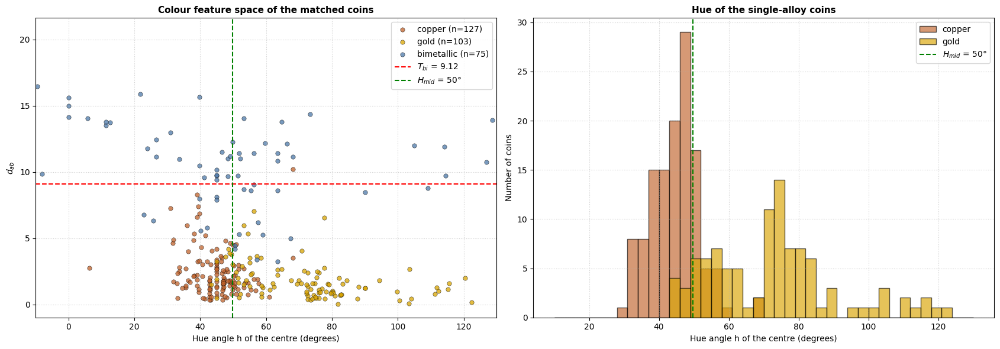

In [24]:
p = PARAMS
single_tp = TP[TP.true_group != "bi"]
cu_hue, au_hue = TP.hue[TP.true_group == "cu"], TP.hue[TP.true_group == "au"]
bi_dab = TP.dab[TP.true_group == "bi"]
print(f"median d_ab: bimetallic {bi_dab.median():.1f}, single alloy {single_tp.dab.median():.1f}; "
      f"bimetallic coins below T_bi: {int((bi_dab < p['T_BI']).sum())}/{len(bi_dab)}")
print(f"copper hue: median {cu_hue.median():.0f} deg, above H_mid: {pct((cu_hue > p['H_MID']).mean())}")
print(f"gold hue: median {au_hue.median():.0f} deg, 10th-90th percentile {au_hue.quantile(0.1):.0f}-{au_hue.quantile(0.9):.0f} deg")
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for g in ("cu", "au", "bi"):
    sub = TP[TP.true_group == g]
    axes[0].scatter(sub.hue, sub.dab, s=28, alpha=0.75, color=GROUP_COLORS[g], edgecolor="black", lw=0.4,
                    label=f"{GROUP_NAMES[g]} (n={len(sub)})")
axes[0].axhline(p["T_BI"], color="red", ls="--", lw=1.5, label=f"$T_{{bi}}$ = {p['T_BI']:.2f}")
axes[0].axvline(p["H_MID"], color="green", ls="--", lw=1.5, label=f"$H_{{mid}}$ = {p['H_MID']:.0f}°")
axes[0].set_xlim(-10, 130)
axes[0].set_xlabel("Hue angle h of the centre (degrees)")
axes[0].set_ylabel("$d_{ab}$")
axes[0].set_title("Colour feature space of the matched coins", fontsize=11, fontweight="bold")
axes[0].grid(True, ls=":", alpha=0.6)
axes[0].legend()

for g in ("cu", "au"):
    axes[1].hist(single_tp[single_tp.true_group == g].hue, bins=np.arange(10, 131, 3), alpha=0.65,
                 color=GROUP_COLORS[g], edgecolor="black", label=GROUP_NAMES[g])
axes[1].axvline(p["H_MID"], color="green", ls="--", lw=1.5, label=f"$H_{{mid}}$ = {p['H_MID']:.0f}°")
axes[1].set_xlabel("Hue angle h of the centre (degrees)")
axes[1].set_ylabel("Number of coins")
axes[1].set_title("Hue of the single-alloy coins", fontsize=11, fontweight="bold")
axes[1].grid(True, ls=":", alpha=0.6)
axes[1].legend()
plt.tight_layout()
plt.show()

### 8.3 What each cue contributes

The classifier rebuilt one cue at a time, on the same matched coins:

| Variant | Decision rule |
|---|---|
| Polar only | nearest template |
| Colour only | colour verdict; for bimetallic coins the sign of $\Delta b$ picks 1€ or 2€; inside copper and gold, a uniform guess (expected accuracy) |
| Colour + polar | first-pass label (no size term) |
| Colour + polar + relative size | the complete pipeline |

A uniform guess among the 8 denominations ($1/8$) is shown as a reference.

Random (1/8): 12.5%  |  Polar only: 73.4%  |  Colour only: 38.3%  |  Colour + polar: 79.0%  |  Colour + polar + relative size: 82.6%


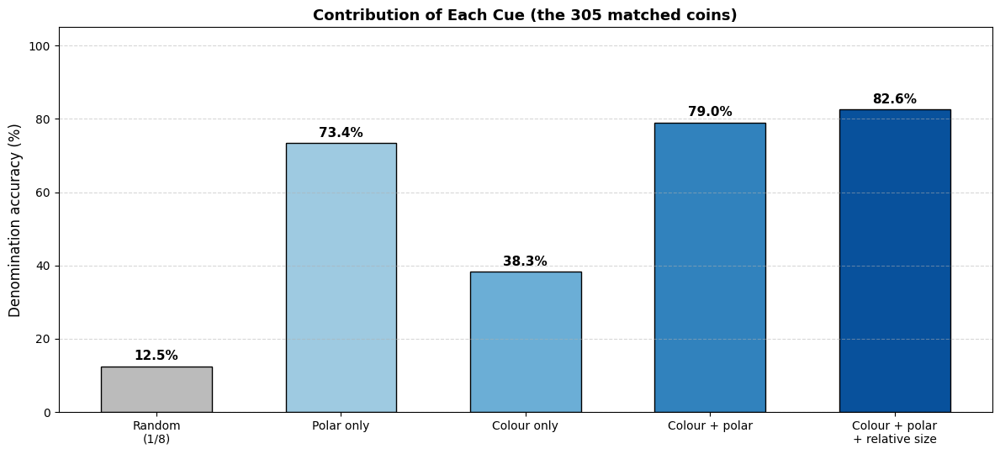

In [25]:
coins_tp = TP.coin.tolist()
y_true = TP.true.to_numpy()
pred_polar = np.array([min(c["dist"], key=c["dist"].get) for c in coins_tp])


def colour_only_expected(group: str, coin: dict, truth: str) -> float:
    # Expected accuracy of: colour verdict, then delta-b for bimetallic coins or a uniform guess inside the family
    if group == "bi":
        return float(("2euro" if coin["features"]["db"] > 0 else "1euro") == truth)
    return (GROUP_OF[truth] == group) / len(GROUPS[group])


acc = {
    "Random\n(1/8)": 100 / 8,
    "Polar only": (pred_polar == y_true).mean() * 100,
    "Colour only": np.mean([colour_only_expected(g, c, t) for g, c, t in zip(TP.colour_group, coins_tp, y_true)]) * 100,
    "Colour + polar": (TP.pred_pass1.to_numpy() == y_true).mean() * 100,
    "Colour + polar\n+ relative size": (TP.pred.to_numpy() == y_true).mean() * 100,
}
print("  |  ".join(f"{k.replace(chr(10), ' ')}: {v:.1f}%" for k, v in acc.items()))
fig, ax = plt.subplots(figsize=(12, 5.5))
bars = ax.bar(list(acc.keys()), list(acc.values()), color=["#bbbbbb", "#9ecae1", "#6baed6", "#3182bd", "#08519c"],
              edgecolor="black", width=0.6)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in acc.values()], fontsize=11, fontweight="bold", padding=3)
ax.set_ylim(0, 105)
ax.set_ylabel("Denomination accuracy (%)", fontsize=12)
ax.set_title(f"Contribution of Each Cue (the {len(TP)} matched coins)", fontsize=13, fontweight="bold")
ax.grid(axis="y", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

The polar descriptor is by far the strongest single cue ($73.4\%$, against $12.5\%$ for chance). Colour alone reaches $38.3\%$: it finds the family and, for bimetallic coins, 1€ vs 2€, but nothing more inside copper and gold. Combining the two gives $79.0\%$, mostly by removing cross-family errors, and relative size adds about $3.6$ more points ($82.6\%$) by untangling same-alloy confusions that neither colour nor a scale-free descriptor can resolve.

### 8.4 Does the circle correction matter for classification?

Refinement (Section 4.3) never adds or removes a circle; it only moves it, which in principle could change which annotation a circle is matched to, but mainly changes *where* colour and descriptor are measured. To isolate its effect, the whole target set is classified again with the raw Hough circles, keeping everything else fixed: the same templates and parameters (built from the references, where refinement moves the circle by at most $3$ px, as printed below) and the same evaluation.

In [26]:
def displacement(c: Circle, h: Circle) -> float:
    # largest of centre shift and radius change, in pixels
    return max(np.hypot(c.cx - h.cx, c.cy - h.cy), abs(c.r - h.r))


# Same pipeline, templates and parameters; only the target circles change (raw Hough proposals)
results_hough = {path.stem: analyse_scene(load_target(path), refine=False) for path in target_paths}
_, _, _, M_hough = evaluate_results(results_hough)

ref_moves = []
for label in DENOMINATIONS:
    refined, raw = detect_coins(ref_images[label], return_raw=True)
    k = refined.index(ref_circles[label])
    ref_moves.append(displacement(refined[k], raw[k]))
tgt_moves = np.array([displacement(coin["circle"], coin["hough"]) for coins in results.values() for coin in coins])
moved = tgt_moves[tgt_moves > 0]
print(f"Reference circles: largest displacement {max(ref_moves):.1f} px")
print(f"Target circles moved by the refinement: {len(moved)}/{len(tgt_moves)}, "
      f"displacement median {np.median(moved):.1f} px, 90th percentile {np.percentile(moved, 90):.1f} px\n")

rows_cmp = [("matched coins", "matched", "{:d}"), ("spurious circles", "spurious", "{:d}"), ("missed coins", "missed", "{:d}"),
            ("family, final label", "family_final", "pct"),
            ("denomination, polar descriptor only", "polar_only", "pct"), ("denomination, full pipeline", "denomination", "pct"),
            ("images with the exact amount", "exact", "pct"), ("mean absolute error / image (EUR)", "mae_eur", "{:.3f}")]
fmt_value = lambda v, f: pct(v) if f == "pct" else f.format(v)
pd.DataFrame({name: [fmt_value(m[key], f) for _, key, f in rows_cmp]
              for name, m in [("Hough only", M_hough), ("Hough + refinement", M)]},
             index=[label for label, _, _ in rows_cmp])

Reference circles: largest displacement 3.0 px
Target circles moved by the refinement: 246/326, displacement median 3.0 px, 90th percentile 6.7 px



,Hough only,Hough + refinement
matched coins,305,305
spurious circles,5,5
missed coins,7,7
"family, final label",93.1%,94.1%
"denomination, polar descriptor only",65.6%,73.4%
"denomination, full pipeline",78.4%,82.6%
images with the exact amount,57.5%,66.1%
mean absolute error / image (EUR),0.124,0.097


Refinement moves $246$ of the $326$ circles, by $3$ px in the median case and up to about $7$ px (90th percentile). Detection is the same with or without it ($305$ matched, $5$ spurious, $7$ missed), and the family of the final label barely changes ($93.1\%$ without, $94.1\%$ with), but the polar descriptor, which samples the coin on a grid centred on the circle, is very sensitive to the centre: its accuracy alone rises from $65.6\%$ to $73.4\%$. For the complete pipeline the correction is worth $4.2$ points of denomination accuracy ($78.4\%$ to $82.6\%$), $8.6$ points of images with the exact amount ($57.5\%$ to $66.1\%$) and lowers the mean absolute error per image from $0.124$ to $0.097$ EUR.

## 9. Closing Remarks

**Outcome.** With classical tools only, the detector (luminance enhancement, median and Non-Local Means denoising, Hough, gradient-based refinement) finds $305$ of the $312$ known coins with $5$ spurious circles (F1 $98.1\%$); the correction of the Hough circles does not change these numbers, but it is worth $4.2$ points of denomination accuracy (Section 8.4). $82.6\%$ of the matched coins get the right denomination, and on the $127$ images without `unk` coins $66.1\%$ of the amounts are exactly right, with a mean absolute error of $0.10$ EUR per image. All the classification parameters come from the reference set and the coin specifications: the colour thresholds and widths from the eight reference coins, $\tau$ from the reference distance matrix, $\lambda$ from the official diameters. The remaining choices ($p$ and $\sigma$ of Grey-Edge, the 90% confidence at the gap, the rules that set $\tau$ and $\lambda$) are heuristics. Errors partly cancel in the sum: on those images the per-image errors add up to $12.27$ EUR in absolute value but only $-6.21$ EUR in signed value, so the total alone overstates the quality of the counter.

**Main takeaway.** For Euro coins every cue is partial. Colour stops at the alloy family; the polar descriptor sees the engraving but suffers from wear and lighting; relative size is very informative but exists only when several coins share a picture. Combining them with soft scores instead of chaining hard thresholds lets each cue repair the uncertain calls of the others, and Section 8.3 shows the gain step by step.

## References

[1] J. van de Weijer, T. Gevers, A. Gijsenij, *Edge-based color constancy*, IEEE Transactions on Image Processing 16(9), pp. 2207–2214, 2007.

[2] G. D. Finlayson, E. Trezzi, *Shades of gray and colour constancy*, Proc. IS&T/SID 12th Color Imaging Conference, pp. 37–41, 2004.